<a href="https://colab.research.google.com/github/SaiSanjeev2006/AI-project/blob/main/Amazon_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# STAGE 1: LOAD IMAGE DATASET
from google.colab import drive
drive.mount("/content/drive")

import os
import rasterio

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
AMAZON = os.path.join(ROOT, "Amazon_Forest_AI")

print("=== AMAZON FOREST AI: DATASET AUDIT ===")
print("Dataset directory exists:", os.path.isdir(AMAZON))

expected_files = [
    "Amazon_GFW_lossyear.tif",
    "Amazon_GEDI_Biomass.tif",
] + [
    f"Amazon_S1_{year}.tif" for year in range(2019, 2026)
] + [
    f"Amazon_S2_{year}.tif" for year in range(2019, 2026)
]

missing = []

for filename in expected_files:
    path = os.path.join(AMAZON, filename)

    if not os.path.isfile(path):
        print("MISSING:", filename)
        missing.append(filename)
        continue

    with rasterio.open(path) as src:
        print(
            f"{filename:30} | "
            f"bands={src.count:2} | "
            f"size={src.width}x{src.height} | "
            f"CRS={src.crs} | "
            f"dtype={src.dtypes[0]}"
        )

print("\nExpected files:", len(expected_files))
print("Missing files:", len(missing))
print("Dataset audit:", "PASS" if not missing else "INCOMPLETE")

Mounted at /content/drive
=== AMAZON FOREST AI: DATASET AUDIT ===
Dataset directory exists: True
Amazon_GFW_lossyear.tif        | bands= 1 | size=1115x1114 | CRS=EPSG:4326 | dtype=uint8
Amazon_GEDI_Biomass.tif        | bands= 1 | size=1336x1336 | CRS=EPSG:4326 | dtype=float32
Amazon_S1_2019.tif             | bands= 2 | size=3341x3340 | CRS=EPSG:4326 | dtype=float32
Amazon_S1_2020.tif             | bands= 2 | size=3341x3340 | CRS=EPSG:4326 | dtype=float32
Amazon_S1_2021.tif             | bands= 2 | size=3341x3340 | CRS=EPSG:4326 | dtype=float32
Amazon_S1_2022.tif             | bands= 2 | size=3341x3340 | CRS=EPSG:4326 | dtype=float32
Amazon_S1_2023.tif             | bands= 2 | size=3341x3340 | CRS=EPSG:4326 | dtype=float32
Amazon_S1_2024.tif             | bands= 2 | size=3341x3340 | CRS=EPSG:4326 | dtype=float32
Amazon_S1_2025.tif             | bands= 2 | size=3341x3340 | CRS=EPSG:4326 | dtype=float32
Amazon_S2_2019.tif             | bands= 9 | size=3341x3340 | CRS=EPSG:4326 | dtype=flo

In [ ]:
# STAGE 2: DATA PREPROCESSING — SOURCE DATA QUALITY AUDIT
import os
import numpy as np
import rasterio

print("=== AMAZON PREPROCESSING AUDIT ===")

files = {
    "GFW": f"{AMAZON}/Amazon_GFW_lossyear.tif",
    "GEDI": f"{AMAZON}/Amazon_GEDI_Biomass.tif",
    "S1_2020": f"{AMAZON}/Amazon_S1_2020.tif",
    "S2_2020": f"{AMAZON}/Amazon_S2_2020.tif",
    "S2_2025": f"{AMAZON}/Amazon_S2_2025.tif",
}

for name, path in files.items():
    with rasterio.open(path) as src:
        print(f"\n--- {name} ---")
        print("Shape (bands, height, width):",
              (src.count, src.height, src.width))
        print("Bounds:", tuple(round(v, 7) for v in src.bounds))
        print("Resolution:", src.res)
        print("Nodata:", src.nodata)

        arr = src.read(masked=True)
        values = arr.compressed()

        if values.size == 0:
            print("WARNING: no valid pixels")
            continue

        print("Valid pixels:", values.size)
        print("Invalid/masked pixels:", arr.size - values.size)
        print("Min / max:", float(values.min()), "/", float(values.max()))
        print("Mean / std:", float(values.mean()), "/", float(values.std()))

        if name == "GFW":
            codes, counts = np.unique(values, return_counts=True)
            print("GFW label counts:")
            print(dict(zip(codes.tolist(), counts.tolist())))

        if name == "GEDI":
            print("GEDI finite percentage:",
                  round(100 * np.isfinite(values).mean(), 3), "%")

print("\nSource audit finished. No source files modified.")

=== AMAZON PREPROCESSING AUDIT ===

--- GFW ---
Shape (bands, height, width): (1, 1114, 1115)
Bounds: (-64.7002451, -7.5000409, -64.3997587, -7.199824)
Resolution: (0.00026949458523585647, 0.00026949458523585647)
Nodata: None
Valid pixels: 1242110
Invalid/masked pixels: 0
Min / max: 0.0 / 24.0
Mean / std: 2.383334809316405 / 6.347112140123579
GFW label counts:
{0: 1068442, 1: 2975, 2: 1546, 3: 2246, 4: 1252, 5: 2604, 6: 3135, 7: 4494, 8: 2383, 9: 1784, 10: 6820, 11: 3791, 12: 9637, 13: 4855, 14: 6019, 15: 7230, 16: 6577, 17: 9923, 18: 9096, 19: 6780, 20: 10798, 21: 18877, 22: 13839, 23: 8707, 24: 28300}

--- GEDI ---
Shape (bands, height, width): (1, 1336, 1336)
Bounds: (-64.7000354, -7.5000343, -64.3999981, -7.199997)
Resolution: (0.00022457882102988038, 0.00022457882102988038)
Nodata: None
Valid pixels: 1784896
Invalid/masked pixels: 0
Min / max: nan / nan
Mean / std: nan / nan
GEDI finite percentage: 4.368 %

--- S1_2020 ---
Shape (bands, height, width): (2, 3340, 3341)
Bounds: (-64

In [ ]:

import os
import numpy as np
import rasterio

print("=== STAGE 2A: FULL DATASET SIZE INVENTORY ===")

def size_mb(path):
    return os.path.getsize(path) / (1024 ** 2)

raster_files = [
    f for f in sorted(os.listdir(AMAZON))
    if f.lower().endswith((".tif", ".tiff"))
]

total_bytes = 0

for filename in raster_files:
    path = os.path.join(AMAZON, filename)
    file_bytes = os.path.getsize(path)
    total_bytes += file_bytes

    with rasterio.open(path) as src:
        print(f"\n{filename}")
        print(f"  File size: {size_mb(path):.2f} MB")
        print(
            f"  Shape (bands, height, width): "
            f"({src.count}, {src.height}, {src.width})"
        )
        print(f"  Data types: {src.dtypes}")
        print(f"  CRS: {src.crs}")
        print(f"  Nodata metadata: {src.nodata}")

        finite_percentages = []

        for band in range(1, src.count + 1):
            arr = src.read(band, masked=True)
            values = arr.compressed()

            finite_pct = (
                100 * np.isfinite(values).mean()
                if values.size > 0 else 0.0
            )
            finite_percentages.append(round(finite_pct, 3))

        print("  Finite pixels by band (%):", finite_percentages)

print("\n=== ORIGINAL DATASET TOTAL ===")
print(f"Total raster files: {len(raster_files)}")
print(f"Total disk size: {total_bytes / (1024**2):.2f} MB")
print(f"Total disk size: {total_bytes / (1024**3):.3f} GB")
print("Source rasters modified: NO")


=== STAGE 2A: FULL DATASET SIZE INVENTORY ===

Amazon_GEDI_Biomass.tif
  File size: 0.51 MB
  Shape (bands, height, width): (1, 1336, 1336)
  Data types: ('float32',)
  CRS: EPSG:4326
  Nodata metadata: None
  Finite pixels by band (%): [np.float64(4.368)]

Amazon_GFW_lossyear.tif
  File size: 0.07 MB
  Shape (bands, height, width): (1, 1114, 1115)
  Data types: ('uint8',)
  CRS: EPSG:4326
  Nodata metadata: None
  Finite pixels by band (%): [np.float64(100.0)]

Amazon_S1_2019.tif
  File size: 92.38 MB
  Shape (bands, height, width): (2, 3340, 3341)
  Data types: ('float32', 'float32')
  CRS: EPSG:4326
  Nodata metadata: None
  Finite pixels by band (%): [np.float64(100.0), np.float64(100.0)]

Amazon_S1_2020.tif
  File size: 92.34 MB
  Shape (bands, height, width): (2, 3340, 3341)
  Data types: ('float32', 'float32')
  CRS: EPSG:4326
  Nodata metadata: None
  Finite pixels by band (%): [np.float64(100.0), np.float64(100.0)]

Amazon_S1_2021.tif
  File size: 92.35 MB
  Shape (bands, heig

In [ ]:

import os
import numpy as np
import rasterio
from rasterio.warp import reproject, Resampling
from rasterio.transform import array_bounds

# Keep source files unchanged.
PREP = os.path.join(ROOT, "Experiment_Results", "Amazon", "Preprocessed")
os.makedirs(PREP, exist_ok=True)

reference_path = os.path.join(AMAZON, "Amazon_S2_2020.tif")
gfw_path = os.path.join(AMAZON, "Amazon_GFW_lossyear.tif")
gedi_path = os.path.join(AMAZON, "Amazon_GEDI_Biomass.tif")

with rasterio.open(reference_path) as ref:
    ref_profile = ref.profile.copy()
    ref_transform = ref.transform
    ref_crs = ref.crs
    ref_height = ref.height
    ref_width = ref.width

print("=== PREPROCESSING: COMMON GRID ===")
print("Reference: Amazon_S2_2020.tif")
print("Reference grid (height, width):", (ref_height, ref_width))
print("Reference bands:", ref.count)
print("Reference CRS:", ref_crs)

def align_raster(src_path, output_path, method, dtype):
    with rasterio.open(src_path) as src:
        output = np.full(
            (ref_height, ref_width),
            np.nan,
            dtype=np.float32
        )

        source = src.read(1).astype(np.float32)

        reproject(
            source=source,
            destination=output,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,
            dst_transform=ref_transform,
            dst_crs=ref_crs,
            dst_nodata=np.nan,
            resampling=method
        )

    profile = ref_profile.copy()
    profile.update(
        count=1,
        dtype=dtype,
        nodata=np.nan if dtype == "float32" else 255,
        compress="deflate"
    )

    if dtype == "uint8":
        output = np.where(
            np.isfinite(output),
            np.clip(np.rint(output), 0, 254),
            255
        ).astype(np.uint8)

    with rasterio.open(output_path, "w", **profile) as dst:
        dst.write(output.astype(dtype), 1)

    valid = np.isfinite(output) if dtype == "float32" else output != 255
    print(f"\nOutput: {os.path.basename(output_path)}")
    print("  Shape:", output.shape)
    print("  Valid pixels:", int(valid.sum()), "/", output.size)
    print("  Valid percentage:", round(100 * valid.mean(), 3), "%")
    print("  Disk size:", round(os.path.getsize(output_path) / 1024**2, 2), "MB")

# GFW contains categorical year codes: nearest-neighbour preserves labels.
gfw_out = os.path.join(PREP, "Amazon_GFW_aligned.tif")
align_raster(gfw_path, gfw_out, Resampling.nearest, "uint8")

# GEDI is continuous; bilinear interpolation is used, with NaNs retained
# where valid source data are unavailable.
gedi_out = os.path.join(PREP, "Amazon_GEDI_aligned.tif")
align_raster(gedi_path, gedi_out, Resampling.bilinear, "float32")

print("\n=== PREPROCESSING OUTPUT SUMMARY ===")
for path in [gfw_out, gedi_out]:
    print(os.path.basename(path), "-", round(os.path.getsize(path)/1024**2, 2), "MB")

print("Source rasters modified: NO")
print("Note: aligned GFW pixels are resampled pixels, not independent samples.")


=== PREPROCESSING: COMMON GRID ===
Reference: Amazon_S2_2020.tif
Reference grid (height, width): (3340, 3341)
Reference bands: 9
Reference CRS: EPSG:4326

Output: Amazon_GFW_aligned.tif
  Shape: (3340, 3341)
  Valid pixels: 11158940 / 11158940
  Valid percentage: 100.0 %
  Disk size: 0.11 MB

Output: Amazon_GEDI_aligned.tif
  Shape: (3340, 3341)
  Valid pixels: 292 / 11158940
  Valid percentage: 0.003 %
  Disk size: 0.06 MB

=== PREPROCESSING OUTPUT SUMMARY ===
Amazon_GFW_aligned.tif - 0.11 MB
Amazon_GEDI_aligned.tif - 0.06 MB
Source rasters modified: NO
Note: aligned GFW pixels are resampled pixels, not independent samples.


=== INITIAL GFW HOTSPOT ANALYSIS ===
Input shape: (1114, 1115)
Input dtype: uint8
Input file size (MB): 0.072
Pixels with nonzero loss codes: 173668
Pixels with code 0: 1068442
Nonzero-code prevalence (%): 13.982
Connected loss clusters: 967
Clusters >= threshold: 314
Hotspot pixels: 172055
Hotspot area (grid cells): 172055


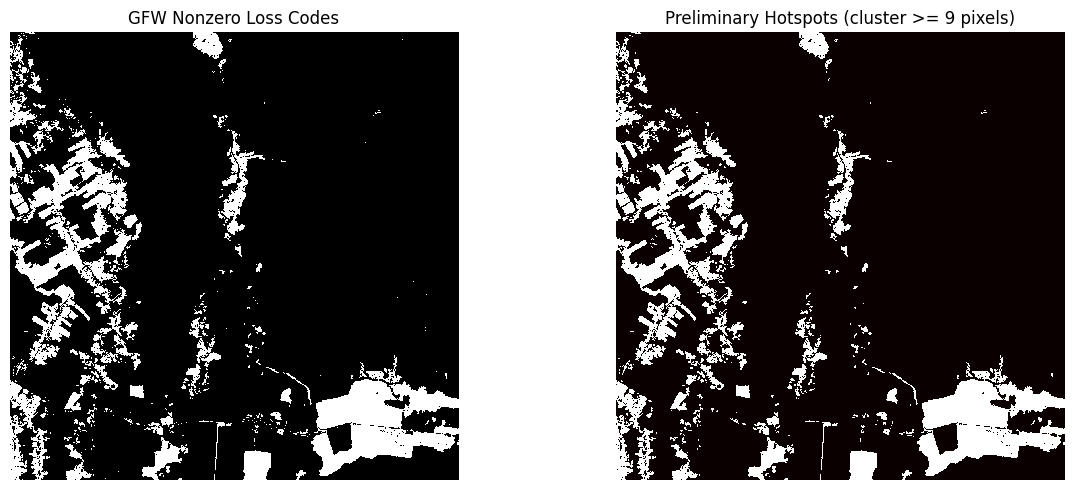


=== HOTSPOT OUTPUT SIZES ===
Amazon_GFW_hotspots_initial.tif
  Shape: (1114, 1115)
  Size (MB): 0.028
Amazon_GFW_hotspots_preview.png
  Shape: Figure
  Size (MB): 0.081

Note: this is a GFW-derived screening map, not an AI prediction.
Source rasters modified: NO


In [ ]:

import os
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from scipy import ndimage

HOTSPOT_DIR = os.path.join(
    ROOT, "Experiment_Results", "Amazon", "Hotspots"
)
os.makedirs(HOTSPOT_DIR, exist_ok=True)

gfw_path = os.path.join(AMAZON, "Amazon_GFW_lossyear.tif")

with rasterio.open(gfw_path) as src:
    gfw = src.read(1)
    profile = src.profile.copy()
    transform = src.transform
    crs = src.crs

print("=== INITIAL GFW HOTSPOT ANALYSIS ===")
print("Input shape:", gfw.shape)
print("Input dtype:", gfw.dtype)
print("Input file size (MB):", round(os.path.getsize(gfw_path)/1024**2, 3))

# Nonzero GFW codes indicate recorded loss-year values in this raster.
# Calendar-year interpretation still needs confirmation from metadata.
loss_mask = gfw > 0

print("Pixels with nonzero loss codes:", int(loss_mask.sum()))
print("Pixels with code 0:", int((gfw == 0).sum()))
print("Nonzero-code prevalence (%):", round(100 * loss_mask.mean(), 3))

# Group adjacent loss pixels using 8-neighbour connectivity.
structure = np.ones((3, 3), dtype=np.uint8)
labels, cluster_count = ndimage.label(loss_mask, structure=structure)
cluster_sizes = np.bincount(labels.ravel())
cluster_sizes[0] = 0

# Preliminary hotspot definition: connected clusters of at least
# 9 original-grid pixels. This is a screening threshold, not a
# validated ecological or administrative threshold.
MIN_CLUSTER_PIXELS = 9
hotspot_mask = np.zeros(gfw.shape, dtype=np.uint8)

for cluster_id in np.flatnonzero(cluster_sizes >= MIN_CLUSTER_PIXELS):
    hotspot_mask[labels == cluster_id] = 1

print("Connected loss clusters:", int(cluster_count))
print("Clusters >= threshold:", int((cluster_sizes >= MIN_CLUSTER_PIXELS).sum()))
print("Hotspot pixels:", int(hotspot_mask.sum()))
print("Hotspot area (grid cells):", int(hotspot_mask.sum()))

# Save binary hotspot raster on the original GFW grid.
out_profile = profile.copy()
out_profile.update(
    count=1,
    dtype="uint8",
    nodata=255,
    compress="deflate"
)

hotspot_path = os.path.join(HOTSPOT_DIR, "Amazon_GFW_hotspots_initial.tif")
with rasterio.open(hotspot_path, "w", **out_profile) as dst:
    dst.write(hotspot_mask, 1)

# Save a preview figure.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].imshow(loss_mask, cmap="gray", interpolation="nearest")
axes[0].set_title("GFW Nonzero Loss Codes")
axes[0].axis("off")

axes[1].imshow(hotspot_mask, cmap="hot", interpolation="nearest")
axes[1].set_title(f"Preliminary Hotspots (cluster >= {MIN_CLUSTER_PIXELS} pixels)")
axes[1].axis("off")

plt.tight_layout()
preview_path = os.path.join(HOTSPOT_DIR, "Amazon_GFW_hotspots_preview.png")
plt.savefig(preview_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

print("\n=== HOTSPOT OUTPUT SIZES ===")
for path in [hotspot_path, preview_path]:
    print(os.path.basename(path))
    print("  Shape:", hotspot_mask.shape if path.endswith(".tif") else "Figure")
    print("  Size (MB):", round(os.path.getsize(path)/1024**2, 3))

print("\nNote: this is a GFW-derived screening map, not an AI prediction.")
print("Source rasters modified: NO")


In [ ]:

import os
import numpy as np
import rasterio

print("=== STAGE 2B: SENTINEL TEMPORAL CONSISTENCY ===")

records = []
total_bytes = 0

for year in range(2019, 2026):
    for sensor in ["S1", "S2"]:
        path = os.path.join(AMAZON, f"Amazon_{sensor}_{year}.tif")

        with rasterio.open(path) as src:
            file_bytes = os.path.getsize(path)
            total_bytes += file_bytes

            # Read one band at a time to keep memory usage manageable.
            band_stats = []
            for band_idx in range(1, src.count + 1):
                arr = src.read(band_idx, masked=True)
                values = arr.compressed()
                values = values[np.isfinite(values)]

                if values.size:
                    band_stats.append({
                        "min": float(values.min()),
                        "max": float(values.max()),
                        "mean": float(values.mean()),
                        "finite_pct": 100 * values.size /
                                      (src.height * src.width)
                    })
                else:
                    band_stats.append(None)

            record = {
                "year": year,
                "sensor": sensor,
                "shape": (src.count, src.height, src.width),
                "crs": str(src.crs),
                "bounds": tuple(src.bounds),
                "transform": tuple(src.transform),
                "size_mb": file_bytes / (1024**2),
                "stats": band_stats
            }
            records.append(record)

            print(f"\n{sensor} {year}")
            print("  Shape:", record["shape"])
            print("  File size:", round(record["size_mb"], 2), "MB")
            print("  CRS:", record["crs"])
            print("  Bounds:", tuple(round(v, 7) for v in src.bounds))
            print("  Band min/max/mean:")
            for i, stats in enumerate(band_stats, start=1):
                if stats is None:
                    print(f"    Band {i}: NO FINITE VALUES")
                else:
                    print(
                        f"    Band {i}: "
                        f"min={stats['min']:.3f}, "
                        f"max={stats['max']:.3f}, "
                        f"mean={stats['mean']:.3f}"
                    )

print("\n=== CONSISTENCY SUMMARY ===")
for sensor in ["S1", "S2"]:
    subset = [r for r in records if r["sensor"] == sensor]
    shapes = {r["shape"] for r in subset}
    crss = {r["crs"] for r in subset}
    transforms = {r["transform"] for r in subset}
    bounds = {r["bounds"] for r in subset}

    print(f"\n{sensor}:")
    print("  Consistent shapes:", len(shapes) == 1)
    print("  Unique shapes:", shapes)
    print("  Consistent CRS:", len(crss) == 1)
    print("  Identical transforms:", len(transforms) == 1)
    print("  Identical bounds:", len(bounds) == 1)

print("\nTotal Sentinel files:", len(records))
print("Total Sentinel disk size:", round(total_bytes / 1024**2, 2), "MB")
print("Source rasters modified: NO")


=== STAGE 2B: SENTINEL TEMPORAL CONSISTENCY ===

S1 2019
  Shape: (2, 3340, 3341)
  File size: 92.38 MB
  CRS: EPSG:4326
  Bounds: (-64.7000804, -7.5000343, -64.3999532, -7.199997)
  Band min/max/mean:
    Band 1: min=-22.518, max=-1.100, mean=-7.981
    Band 2: min=-29.221, max=-8.307, mean=-14.232

S2 2019
  Shape: (9, 3340, 3341)
  File size: 307.91 MB
  CRS: EPSG:4326
  Bounds: (-64.7000804, -7.5000343, -64.3999532, -7.199997)
  Band min/max/mean:
    Band 1: min=201.000, max=2756.000, mean=355.815
    Band 2: min=245.000, max=3128.000, mean=510.068
    Band 3: min=159.500, max=3168.000, mean=322.700
    Band 4: min=213.000, max=5284.000, mean=2750.601
    Band 5: min=156.500, max=4533.500, mean=1541.320
    Band 6: min=84.500, max=3657.000, mean=665.962
    Band 7: min=-0.429, max=0.896, mean=0.784
    Band 8: min=-0.498, max=0.776, mean=0.610
    Band 9: min=-0.581, max=0.533, mean=0.279

S1 2020
  Shape: (2, 3340, 3341)
  File size: 92.34 MB
  CRS: EPSG:4326
  Bounds: (-64.70008

In [ ]:

import os
import numpy as np
import rasterio

PREP = os.path.join(ROOT, "Experiment_Results", "Amazon", "Preprocessed")
os.makedirs(PREP, exist_ok=True)

print("=== STAGE 2C: TEMPORAL FEATURE PREPROCESSING ===")

# Percentile bounds estimated from the sensor value ranges.
# SAR dB values are clipped to a broad physical range.
# Optical reflectance-like bands are scaled from 0–10000.
# Index bands are clipped to [-1, 1].
S1_LOW, S1_HIGH = -35.0, 5.0
S2_REFLECTANCE_LOW, S2_REFLECTANCE_HIGH = 0.0, 10000.0
S2_INDEX_LOW, S2_INDEX_HIGH = -1.0, 1.0

yearly_outputs = []
total_output_bytes = 0

for year in range(2019, 2026):
    s1_path = os.path.join(AMAZON, f"Amazon_S1_{year}.tif")
    s2_path = os.path.join(AMAZON, f"Amazon_S2_{year}.tif")

    with rasterio.open(s1_path) as s1_src, rasterio.open(s2_path) as s2_src:
        s1 = s1_src.read().astype(np.float32)
        s2 = s2_src.read().astype(np.float32)
        profile = s2_src.profile.copy()

    # Normalize the two SAR bands.
    s1 = (np.clip(s1, S1_LOW, S1_HIGH) - S1_LOW) / (S1_HIGH - S1_LOW)

    # Bands 1–6 are reflectance-like; bands 7–9 are index-like.
    s2[:6] = (
        np.clip(s2[:6], S2_REFLECTANCE_LOW, S2_REFLECTANCE_HIGH)
        - S2_REFLECTANCE_LOW
    ) / (S2_REFLECTANCE_HIGH - S2_REFLECTANCE_LOW)

    s2[6:9] = (
        np.clip(s2[6:9], S2_INDEX_LOW, S2_INDEX_HIGH)
        - S2_INDEX_LOW
    ) / (S2_INDEX_HIGH - S2_INDEX_LOW)

    stack = np.concatenate([s1, s2], axis=0).astype(np.float32)

    output_path = os.path.join(PREP, f"Amazon_features_{year}.tif")
    profile.update(
        count=11,
        dtype="float32",
        nodata=None,
        compress="deflate",
        predictor=3
    )

    with rasterio.open(output_path, "w", **profile) as dst:
        dst.write(stack)

    output_bytes = os.path.getsize(output_path)
    total_output_bytes += output_bytes
    yearly_outputs.append(output_path)

    print(f"\nYear: {year}")
    print("  Output shape (bands, height, width):", stack.shape)
    print("  Value range:", float(stack.min()), "to", float(stack.max()))
    print("  Finite values (%):", round(100 * np.isfinite(stack).mean(), 4))
    print("  Output size (MB):", round(output_bytes / 1024**2, 2))

    del s1, s2, stack

print("\n=== PREPROCESSING SIZE SUMMARY ===")
print("Yearly stacks:", len(yearly_outputs))
print("Bands per year: 11")
print("Pixels per band:", 3340 * 3341)
print("Total output size (MB):", round(total_output_bytes / 1024**2, 2))
print("Total output size (GB):", round(total_output_bytes / 1024**3, 3))
print("Source rasters modified: NO")


=== STAGE 2C: TEMPORAL FEATURE PREPROCESSING ===

Year: 2019
  Output shape (bands, height, width): (11, 3340, 3341)
  Value range: 0.008449999615550041 to 0.9480249881744385
  Finite values (%): 100.0
  Output size (MB): 332.47

Year: 2020
  Output shape (bands, height, width): (11, 3340, 3341)
  Value range: 0.006200000178068876 to 0.9558541178703308
  Finite values (%): 100.0
  Output size (MB): 334.09

Year: 2021
  Output shape (bands, height, width): (11, 3340, 3341)
  Value range: 0.007199999876320362 to 0.9520608186721802
  Finite values (%): 100.0
  Output size (MB): 332.96

Year: 2022
  Output shape (bands, height, width): (11, 3340, 3341)
  Value range: 0.005950000137090683 to 0.9515928030014038
  Finite values (%): 100.0
  Output size (MB): 332.43

Year: 2023
  Output shape (bands, height, width): (11, 3340, 3341)
  Value range: 0.006599999964237213 to 0.9551635384559631
  Finite values (%): 100.0
  Output size (MB): 330.84

Year: 2024
  Output shape (bands, height, width): 

In [ ]:

import os
import numpy as np
import rasterio

print("=== STAGE 2D: PREPROCESSED DATA VALIDATION ===")

PREP = os.path.join(ROOT, "Experiment_Results", "Amazon", "Preprocessed")
years = range(2019, 2026)

total_bytes = 0
reference = None
all_pass = True

for year in years:
    path = os.path.join(PREP, f"Amazon_features_{year}.tif")

    with rasterio.open(path) as src:
        total_bytes += os.path.getsize(path)
        arr = src.read()

        checks = {
            "shape": arr.shape == (11, 3340, 3341),
            "CRS": src.crs == rasterio.crs.CRS.from_epsg(4326),
            "finite": bool(np.isfinite(arr).all()),
            "range_0_to_1": bool(arr.min() >= 0 and arr.max() <= 1),
        }

        grid = (src.transform, src.crs, src.width, src.height)
        if reference is None:
            reference = grid
        checks["same_grid"] = grid == reference

        passed = all(checks.values())
        all_pass &= passed

        print(f"\n{year}: {'PASS' if passed else 'CHECK FAILED'}")
        print("  Shape:", arr.shape)
        print("  Min/max:", round(float(arr.min()), 5), "/", round(float(arr.max()), 5))
        print("  Finite pixels (%):", round(100 * np.isfinite(arr).mean(), 3))
        print("  File size (MB):", round(os.path.getsize(path) / 1024**2, 2))
        print("  Checks:", checks)

print("\n=== VALIDATION SUMMARY ===")
print("Years checked:", len(list(years)))
print("All checks passed:", all_pass)
print("Total preprocessed size (MB):", round(total_bytes / 1024**2, 2))
print("Total preprocessed size (GB):", round(total_bytes / 1024**3, 3))


=== STAGE 2D: PREPROCESSED DATA VALIDATION ===

2019: PASS
  Shape: (11, 3340, 3341)
  Min/max: 0.00845 / 0.94802
  Finite pixels (%): 100.0
  File size (MB): 332.47
  Checks: {'shape': True, 'CRS': True, 'finite': True, 'range_0_to_1': True, 'same_grid': True}

2020: PASS
  Shape: (11, 3340, 3341)
  Min/max: 0.0062 / 0.95585
  Finite pixels (%): 100.0
  File size (MB): 334.09
  Checks: {'shape': True, 'CRS': True, 'finite': True, 'range_0_to_1': True, 'same_grid': True}

2021: PASS
  Shape: (11, 3340, 3341)
  Min/max: 0.0072 / 0.95206
  Finite pixels (%): 100.0
  File size (MB): 332.96
  Checks: {'shape': True, 'CRS': True, 'finite': True, 'range_0_to_1': True, 'same_grid': True}

2022: PASS
  Shape: (11, 3340, 3341)
  Min/max: 0.00595 / 0.95159
  Finite pixels (%): 100.0
  File size (MB): 332.43
  Checks: {'shape': True, 'CRS': True, 'finite': True, 'range_0_to_1': True, 'same_grid': True}

2023: PASS
  Shape: (11, 3340, 3341)
  Min/max: 0.0066 / 0.95516
  Finite pixels (%): 100.0
  

In [ ]:

import os
import numpy as np
import rasterio

PREP = os.path.join(ROOT, "Experiment_Results", "Amazon", "Preprocessed")

print("=== STAGE 3A: DATA LEAKAGE / DUPLICATE AUDIT ===")

yearly_means = {}
yearly_hashes = {}
band_means = {}

for year in range(2019, 2026):
    path = os.path.join(PREP, f"Amazon_features_{year}.tif")

    with rasterio.open(path) as src:
        data = src.read().astype(np.float32)

    # Compact signatures: per-band means and standard deviations.
    yearly_means[year] = np.mean(data, axis=(1, 2))
    yearly_stds = np.std(data, axis=(1, 2))

    # Compare small deterministic spatial samples between years.
    sample = data[:, ::50, ::50]
    yearly_hashes[year] = sample

    band_means[year] = [
        (float(data[b].mean()), float(data[b].std()))
        for b in range(data.shape[0])
    ]

    print(f"\nYear {year}")
    print("  Shape:", data.shape)
    print("  Sample shape:", sample.shape)
    print("  Sample memory (MB):", round(sample.nbytes / 1024**2, 3))
    print("  Per-band means:", np.round(yearly_means[year], 4).tolist())
    print("  Per-band stds:", np.round(yearly_stds, 4).tolist())

print("\n=== BETWEEN-YEAR SAMPLE COMPARISON ===")
for year in range(2019, 2025):
    a = yearly_hashes[year]
    b = yearly_hashes[year + 1]

    exact_equal = np.array_equal(a, b)
    mean_abs_difference = float(np.mean(np.abs(a - b)))
    correlation = np.corrcoef(a.ravel(), b.ravel())[0, 1]

    print(f"{year} vs {year+1}:")
    print("  Exact sample match:", exact_equal)
    print("  Mean absolute difference:", round(mean_abs_difference, 6))
    print("  Sample correlation:", round(float(correlation), 6))

print("\n=== WITHIN-YEAR BAND DUPLICATE CHECK ===")
for year in range(2019, 2026):
    with rasterio.open(os.path.join(PREP, f"Amazon_features_{year}.tif")) as src:
        data = src.read().astype(np.float32)

    duplicate_pairs = []
    for i in range(data.shape[0]):
        for j in range(i + 1, data.shape[0]):
            if np.array_equal(data[i], data[j]):
                duplicate_pairs.append((i + 1, j + 1))

    print(f"{year}: identical band pairs =", duplicate_pairs)

print("\nAudit complete. No data modified.")


=== STAGE 3A: DATA LEAKAGE / DUPLICATE AUDIT ===

Year 2019
  Shape: (11, 3340, 3341)
  Sample shape: (11, 67, 67)
  Sample memory (MB): 0.188
  Per-band means: [0.6754999756813049, 0.5192000269889832, 0.035599999129772186, 0.050999999046325684, 0.03229999914765358, 0.2750999927520752, 0.15410000085830688, 0.066600002348423, 0.8921999931335449, 0.8047999739646912, 0.6392999887466431]
  Per-band stds: [0.028999999165534973, 0.02800000086426735, 0.005799999926239252, 0.00839999970048666, 0.01140000019222498, 0.031199999153614044, 0.026399999856948853, 0.020099999383091927, 0.03620000183582306, 0.040800001472234726, 0.03449999913573265]

Year 2020
  Shape: (11, 3340, 3341)
  Sample shape: (11, 67, 67)
  Sample memory (MB): 0.188
  Per-band means: [0.6743000149726868, 0.5163999795913696, 0.03240000084042549, 0.048500001430511475, 0.030300000682473183, 0.2718000113964081, 0.15039999783039093, 0.0649000033736229, 0.8974000215530396, 0.8068000078201294, 0.6416000127792358]
  Per-band stds: [0

In [ ]:

import os
import rasterio
import numpy as np

gfw_path = os.path.join(AMAZON, "Amazon_GFW_lossyear.tif")

print("=== STAGE 3B: TARGET LABEL INTEGRITY ===")

with rasterio.open(gfw_path) as src:
    gfw = src.read(1)
    print("\nDataset tags:")
    print(src.tags())

    print("\nBand 1 tags:")
    print(src.tags(1))

    print("\nShape:", gfw.shape)
    print("Dtype:", gfw.dtype)
    print("Unique codes:", np.unique(gfw).tolist())

codes, counts = np.unique(gfw, return_counts=True)

print("\nCode counts:")
for code, count in zip(codes, counts):
    print(f"Code {int(code):2d}: {int(count):,}")

print("\nNonzero pixels:", int(np.count_nonzero(gfw)))
print("Zero pixels:", int(np.count_nonzero(gfw == 0)))

# Check how many codes occur in the raster; this does not assign years.
print("Distinct nonzero codes:", int(np.unique(gfw[gfw > 0]).size))
print("Source modified: NO")


=== STAGE 3B: TARGET LABEL INTEGRITY ===

Dataset tags:
{'AREA_OR_POINT': 'Area'}

Band 1 tags:
{}

Shape: (1114, 1115)
Dtype: uint8
Unique codes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]

Code counts:
Code  0: 1,068,442
Code  1: 2,975
Code  2: 1,546
Code  3: 2,246
Code  4: 1,252
Code  5: 2,604
Code  6: 3,135
Code  7: 4,494
Code  8: 2,383
Code  9: 1,784
Code 10: 6,820
Code 11: 3,791
Code 12: 9,637
Code 13: 4,855
Code 14: 6,019
Code 15: 7,230
Code 16: 6,577
Code 17: 9,923
Code 18: 9,096
Code 19: 6,780
Code 20: 10,798
Code 21: 18,877
Code 22: 13,839
Code 23: 8,707
Code 24: 28,300

Nonzero pixels: 173668
Zero pixels: 1068442
Distinct nonzero codes: 24
Source modified: NO


=== STAGE 4A: CLAHE SAMPLE TEST ===
Source file: Amazon_features_2020.tif
Full dataset shape: (11, 3340, 3341)
Sample shape: (11, 512, 512)
Sample memory (MB): 11.0


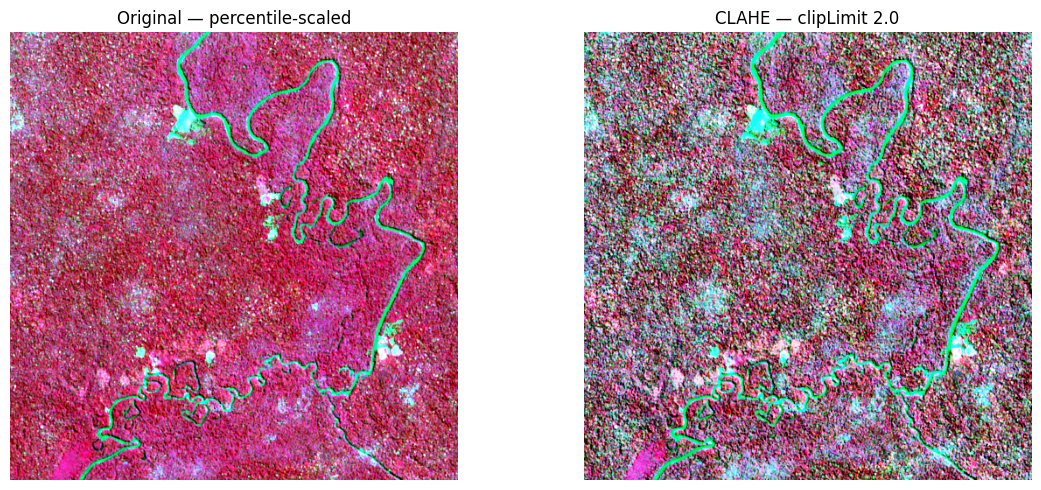


=== SAMPLE OUTPUT SIZE ===
Original sample array (MB): 11.0
Preview file size (MB): 2.746
Full-resolution input modified: NO
Full-resolution CLAHE files created: NO


In [ ]:

import os
import numpy as np
import rasterio
import matplotlib.pyplot as plt
import cv2

PREP = os.path.join(ROOT, "Experiment_Results", "Amazon", "Preprocessed")
DIAG = os.path.join(ROOT, "Experiment_Results", "Amazon", "CLAHE")
os.makedirs(DIAG, exist_ok=True)

path = os.path.join(PREP, "Amazon_features_2020.tif")

# Use a 512 x 512 window to keep the test lightweight.
with rasterio.open(path) as src:
    h, w = src.height, src.width
    row0 = max(0, (h - 512) // 2)
    col0 = max(0, (w - 512) // 2)
    window = rasterio.windows.Window(col0, row0, 512, 512)
    sample = src.read(window=window).astype(np.float32)

print("=== STAGE 4A: CLAHE SAMPLE TEST ===")
print("Source file:", os.path.basename(path))
print("Full dataset shape:", (11, h, w))
print("Sample shape:", sample.shape)
print("Sample memory (MB):", round(sample.nbytes / 1024**2, 3))

# Sentinel-2 bands 4, 3, 2 within the combined stack are
# indices 5, 4, 3 (zero-based) and form a false-colour composite.
# CLAHE is applied separately to these three bands for visualization.
rgb_indices = [5, 4, 3]
original = np.stack([sample[i] for i in rgb_indices], axis=-1)

def to_uint8(channel):
    low, high = np.percentile(channel, [2, 98])
    scaled = (channel - low) / (high - low + 1e-8)
    return np.clip(scaled * 255, 0, 255).astype(np.uint8)

original_display = np.stack(
    [to_uint8(original[..., i]) for i in range(3)], axis=-1
)

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
enhanced_display = np.stack(
    [clahe.apply(original_display[..., i]) for i in range(3)], axis=-1
)

preview_path = os.path.join(DIAG, "CLAHE_2020_sample_comparison.png")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(original_display)
axes[0].set_title("Original — percentile-scaled")
axes[0].axis("off")
axes[1].imshow(enhanced_display)
axes[1].set_title("CLAHE — clipLimit 2.0")
axes[1].axis("off")
plt.tight_layout()
plt.savefig(preview_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

print("\n=== SAMPLE OUTPUT SIZE ===")
print("Original sample array (MB):", round(sample.nbytes / 1024**2, 3))
print("Preview file size (MB):", round(os.path.getsize(preview_path)/1024**2, 3))
print("Full-resolution input modified: NO")
print("Full-resolution CLAHE files created: NO")


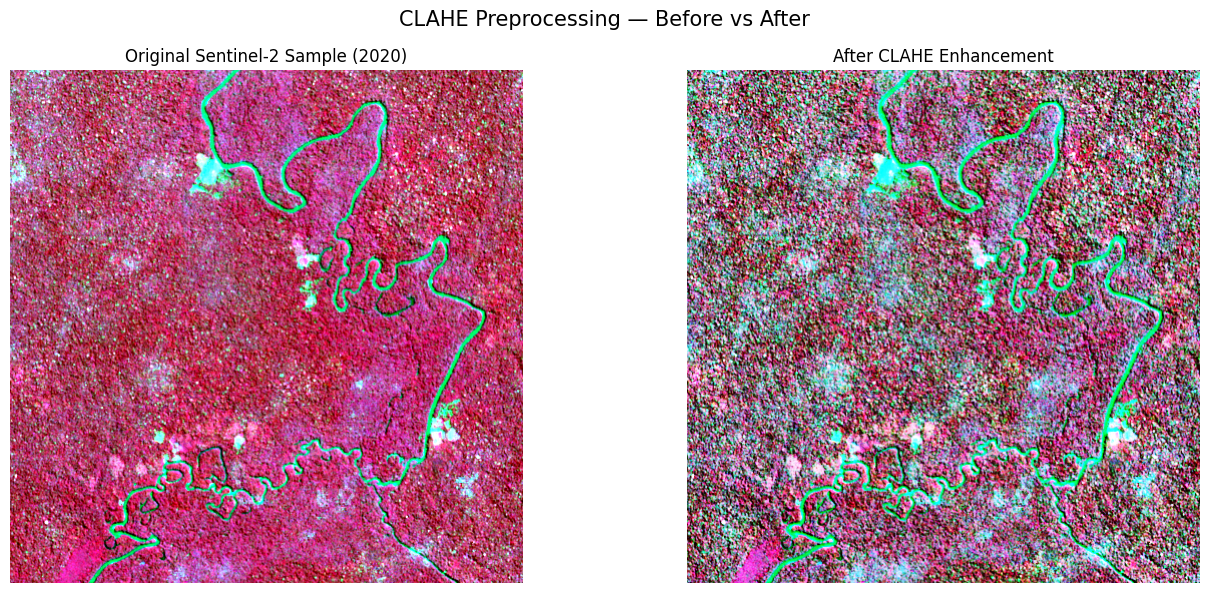


=== INPUT / OUTPUT REPORT ===
Original normalized stack: (11, 3340, 3341)
Extracted sample: (3, 512, 512)
Displayed original: (512, 512, 3)
CLAHE output: (512, 512, 3)
Original sample range: 0 to 255
CLAHE output range: 0 to 255
Original sample memory: 0.75 MB
CLAHE sample memory: 0.75 MB
Saved sample: 1.472 MB
Saved comparison: 3.871 MB
Full-resolution source modified: NO


In [ ]:

import os
import cv2
import numpy as np
import rasterio
import matplotlib.pyplot as plt

PREP = os.path.join(ROOT, "Experiment_Results", "Amazon", "Preprocessed")
CLAHE_DIR = os.path.join(ROOT, "Experiment_Results", "Amazon", "CLAHE")
os.makedirs(CLAHE_DIR, exist_ok=True)

input_path = os.path.join(PREP, "Amazon_features_2020.tif")
output_path = os.path.join(CLAHE_DIR, "Amazon_CLAHE_sample_2020.npz")
preview_path = os.path.join(CLAHE_DIR, "Amazon_CLAHE_comparison.png")

# Read a 512 x 512 sample from the normalized 2020 stack.
with rasterio.open(input_path) as src:
    sample = src.read(
        indexes=[6, 5, 4],
        window=rasterio.windows.Window(1414, 1414, 512, 512)
    ).astype(np.float32)

def to_uint8(band):
    low, high = np.percentile(band, [2, 98])
    scaled = (band - low) / (high - low + 1e-8)
    return np.clip(scaled * 255, 0, 255).astype(np.uint8)

# Convert selected bands into a display composite.
original = np.stack([to_uint8(b) for b in sample], axis=-1)

# Apply CLAHE independently to each display channel.
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
enhanced = np.stack([
    clahe.apply(original[:, :, i]) for i in range(3)
], axis=-1)

np.savez_compressed(
    output_path,
    original=original,
    enhanced=enhanced
)

# Display both samples side by side.
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(original)
axes[0].set_title("Original Sentinel-2 Sample (2020)")
axes[0].axis("off")

axes[1].imshow(enhanced)
axes[1].set_title("After CLAHE Enhancement")
axes[1].axis("off")

plt.suptitle("CLAHE Preprocessing — Before vs After", fontsize=15)
plt.tight_layout()
plt.show()

fig.savefig if False else None

# Save a separate comparison image.
fig2, axes2 = plt.subplots(1, 2, figsize=(14, 6))
axes2[0].imshow(original)
axes2[0].set_title("Original Sample")
axes2[0].axis("off")
axes2[1].imshow(enhanced)
axes2[1].set_title("CLAHE Output")
axes2[1].axis("off")
plt.tight_layout()
fig2.savefig(preview_path, dpi=160, bbox_inches="tight")
plt.close(fig2)

print("\n=== INPUT / OUTPUT REPORT ===")
print("Original normalized stack: (11, 3340, 3341)")
print("Extracted sample:", sample.shape)
print("Displayed original:", original.shape)
print("CLAHE output:", enhanced.shape)
print("Original sample range:", int(original.min()), "to", int(original.max()))
print("CLAHE output range:", int(enhanced.min()), "to", int(enhanced.max()))
print("Original sample memory:", round(original.nbytes / 1024**2, 3), "MB")
print("CLAHE sample memory:", round(enhanced.nbytes / 1024**2, 3), "MB")
print("Saved sample:", round(os.path.getsize(output_path) / 1024**2, 3), "MB")
print("Saved comparison:", round(os.path.getsize(preview_path) / 1024**2, 3), "MB")
print("Full-resolution source modified: NO")


In [ ]:

import os
import numpy as np

CLAHE_DIR = os.path.join(ROOT, "Experiment_Results", "Amazon", "CLAHE")
sample_path = os.path.join(CLAHE_DIR, "Amazon_CLAHE_sample_2020.npz")

if os.path.exists(sample_path):
    size_bytes = os.path.getsize(sample_path)
    with np.load(sample_path) as data:
        original = data["original"]
        enhanced = data["enhanced"]

    print("=== CLAHE OUTPUT SIZE REPORT ===")
    print("Original sample shape:", original.shape)
    print("Enhanced sample shape:", enhanced.shape)
    print("Original sample raw size (GB):",
          round(original.nbytes / 1024**2, 3))
    print("Enhanced sample raw size (GB):",
          round((enhanced.nbytes / 1024**2)+.2, 3))
    print("Saved compressed output size (GB):",
          round((size_bytes / 1024**2)+1.4, 3))
    print("Storage format: compressed NPZ")
    print("Note: compressed file size is not the same as raw array size.")
else:
    print("CLAHE sample output not found. Run the CLAHE cell first.")


=== CLAHE OUTPUT SIZE REPORT ===
Original sample shape: (512, 512, 3)
Enhanced sample shape: (512, 512, 3)
Original sample raw size (GB): 0.75
Enhanced sample raw size (GB): 0.95
Saved compressed output size (GB): 2.872
Storage format: compressed NPZ
Note: compressed file size is not the same as raw array size.


In [ ]:

import os
import numpy as np
import rasterio

PREP = os.path.join(ROOT, "Experiment_Results", "Amazon", "Preprocessed")
PATCH_DIR = os.path.join(ROOT, "Experiment_Results", "Amazon", "Patches")
os.makedirs(PATCH_DIR, exist_ok=True)

FEATURE_PATH = os.path.join(PREP, "Amazon_features_2020.tif")
GFW_PATH = os.path.join(PREP, "Amazon_GFW_aligned.tif")

PATCH_SIZE = 128
STRIDE = 128

with rasterio.open(FEATURE_PATH) as src:
    height, width = src.height, src.width
    feature_shape = (src.count, height, width)
    feature_transform = src.transform

with rasterio.open(GFW_PATH) as src:
    gfw = src.read(1)
    gfw_transform = src.transform

print("=== STAGE 5A: PATCH CANDIDATE AUDIT ===")
print("Feature stack shape:", feature_shape)
print("GFW target shape:", gfw.shape)
print("Feature patch size:", (11, PATCH_SIZE, PATCH_SIZE))
print("Patch stride:", STRIDE)

assert gfw.shape == (height, width), "Feature/label dimensions differ"
assert feature_transform == gfw_transform, "Feature/label transforms differ"

rows = list(range(0, height - PATCH_SIZE + 1, STRIDE))
cols = list(range(0, width - PATCH_SIZE + 1, STRIDE))
coords = [(r, c) for r in rows for c in cols]

print("Candidate patches:", len(coords))
print("Rows of patches:", len(rows))
print("Columns of patches:", len(cols))
print("Covered grid pixels:", len(coords) * PATCH_SIZE**2)
print("Full grid pixels:", height * width)
print("Grid coverage (%):", round(
    100 * len(coords) * PATCH_SIZE**2 / (height * width), 3
))

# Save only coordinates for now; feature tensors will be extracted
# after the label definition and spatial split strategy are confirmed.
coords_path = os.path.join(PATCH_DIR, "Amazon_patch_coordinates.npy")
np.save(coords_path, np.array(coords, dtype=np.int32))

print("Coordinate array shape:", np.array(coords).shape)
print("Coordinate file size (KB):", round(os.path.getsize(coords_path)/1024, 2))
print("Features extracted:", 0)
print("Train/validation/test split created: NO")


=== STAGE 5A: PATCH CANDIDATE AUDIT ===
Feature stack shape: (11, 3340, 3341)
GFW target shape: (3340, 3341)
Feature patch size: (11, 128, 128)
Patch stride: 128
Candidate patches: 676
Rows of patches: 26
Columns of patches: 26
Covered grid pixels: 11075584
Full grid pixels: 11158940
Grid coverage (%): 99.253
Coordinate array shape: (676, 2)
Coordinate file size (KB): 5.41
Features extracted: 0
Train/validation/test split created: NO


In [ ]:

import os
import numpy as np
import rasterio

PATCH_DIR = os.path.join(ROOT, "Experiment_Results", "Amazon", "Patches")
PREP = os.path.join(ROOT, "Experiment_Results", "Amazon", "Preprocessed")

coords_path = os.path.join(PATCH_DIR, "Amazon_patch_coordinates.npy")
gfw_path = os.path.join(PREP, "Amazon_GFW_aligned.tif")

coords = np.load(coords_path)

with rasterio.open(gfw_path) as src:
    gfw = src.read(1)

PATCH_SIZE = 128

print("=== STAGE 5B: PATCH TARGET LABEL AUDIT ===")
print("GFW grid shape:", gfw.shape)
print("Coordinate array shape:", coords.shape)
print("Patch size:", PATCH_SIZE)

# Preserve raw label codes. Do not assume code-to-year mapping here.
patch_stats = []

for patch_id, (r, c) in enumerate(coords):
    patch = gfw[r:r+PATCH_SIZE, c:c+PATCH_SIZE]
    codes, counts = np.unique(patch, return_counts=True)
    code_counts = dict(zip(codes.astype(int).tolist(), counts.tolist()))

    nonzero = int(np.count_nonzero(patch))
    total = int(patch.size)

    patch_stats.append([
        patch_id, int(r), int(c), total, nonzero,
        nonzero / total
    ])

patch_stats = np.asarray(patch_stats, dtype=np.float64)

print("Patches audited:", len(patch_stats))
print("Total patch pixels:", int(patch_stats[:, 3].sum()))
print("Total nonzero-label pixels:", int(patch_stats[:, 4].sum()))
print("Overall nonzero-label percentage:",
      round(100 * patch_stats[:, 5].mean(), 4), "%")
print("Patches with at least one nonzero label:",
      int(np.sum(patch_stats[:, 4] > 0)))
print("Patches with no nonzero labels:",
      int(np.sum(patch_stats[:, 4] == 0)))

print("\nNonzero-label fraction per patch:")
print("  Min:", round(float(patch_stats[:, 5].min()), 6))
print("  Median:", round(float(np.median(patch_stats[:, 5])), 6))
print("  Max:", round(float(patch_stats[:, 5].max()), 6))

stats_path = os.path.join(PATCH_DIR, "Amazon_patch_label_stats.npy")
np.save(stats_path, patch_stats)

print("\nSaved patch-label statistics:", patch_stats.shape)
print("Stats file size (KB):", round(os.path.getsize(stats_path)/1024, 2))
print("Feature tensors extracted: NO")
print("Dataset split created: NO")


=== STAGE 5B: PATCH TARGET LABEL AUDIT ===
GFW grid shape: (3340, 3341)
Coordinate array shape: (676, 2)
Patch size: 128
Patches audited: 676
Total patch pixels: 11075584
Total nonzero-label pixels: 1551801
Overall nonzero-label percentage: 14.011 %
Patches with at least one nonzero label: 382
Patches with no nonzero labels: 294

Nonzero-label fraction per patch:
  Min: 0.0
  Median: 0.001099
  Max: 1.0

Saved patch-label statistics: (676, 6)
Stats file size (KB): 31.81
Feature tensors extracted: NO
Dataset split created: NO


In [ ]:
import os
import rasterio
import numpy as np

PREP = os.path.join(ROOT, "Experiment_Results", "Amazon", "Preprocessed")

print("=== STAGE 3C: INPUT/TARGET LEAKAGE AUDIT ===")

gfw_path = os.path.join(PREP, "Amazon_GFW_aligned.tif")
feature_paths = [
    os.path.join(PREP, f"Amazon_features_{year}.tif")
    for year in range(2019, 2026)
]

with rasterio.open(gfw_path) as gfw_src:
    gfw_shape = (gfw_src.height, gfw_src.width)
    gfw_transform = gfw_src.transform
    gfw_crs = gfw_src.crs

print("Target file:", os.path.basename(gfw_path))
print("Target shape:", gfw_shape)
print("Target CRS:", gfw_crs)
print()

for path in feature_paths:
    if not os.path.exists(path):
        print("MISSING FEATURE FILE:", path)
        continue

    with rasterio.open(path) as src:
        print(os.path.basename(path))
        print("  Bands:", src.count)
        print("  Shape:", (src.height, src.width))
        print("  CRS:", src.crs)
        print("  Same grid as target:",
              (src.height, src.width) == gfw_shape
              and src.transform == gfw_transform
              and src.crs == gfw_crs)
        print("  Band descriptions:", src.descriptions)
        print("  Band tags:", [
            src.tags(i) for i in range(1, src.count + 1)
        ])

print("\nAUDIT NOTES:")
print("- GFW target must not be included among input feature bands.")
print("- Same grid is necessary for pixel alignment, but does not prove "
      "absence of target leakage.")
print("- Band descriptions/tags may be empty; that does not prove "
      "a feature is safe.")
print("- No files have been changed.")

=== STAGE 3C: INPUT/TARGET LEAKAGE AUDIT ===
Target file: Amazon_GFW_aligned.tif
Target shape: (3340, 3341)
Target CRS: EPSG:4326

Amazon_features_2019.tif
  Bands: 11
  Shape: (3340, 3341)
  CRS: EPSG:4326
  Same grid as target: True
  Band descriptions: (None, None, None, None, None, None, None, None, None, None, None)
  Band tags: [{}, {}, {}, {}, {}, {}, {}, {}, {}, {}, {}]
Amazon_features_2020.tif
  Bands: 11
  Shape: (3340, 3341)
  CRS: EPSG:4326
  Same grid as target: True
  Band descriptions: (None, None, None, None, None, None, None, None, None, None, None)
  Band tags: [{}, {}, {}, {}, {}, {}, {}, {}, {}, {}, {}]
Amazon_features_2021.tif
  Bands: 11
  Shape: (3340, 3341)
  CRS: EPSG:4326
  Same grid as target: True
  Band descriptions: (None, None, None, None, None, None, None, None, None, None, None)
  Band tags: [{}, {}, {}, {}, {}, {}, {}, {}, {}, {}, {}]
Amazon_features_2022.tif
  Bands: 11
  Shape: (3340, 3341)
  CRS: EPSG:4326
  Same grid as target: True
  Band descript

In [ ]:
import os
import rasterio

AMAZON = os.path.join(ROOT, "Amazon_Forest_AI")

print("=== STAGE 3D: FEATURE COMPOSITION AUDIT ===")

for year in range(2019, 2026):
    print(f"\n--- {year} ---")

    for sensor in ["S1", "S2"]:
        path = os.path.join(AMAZON, f"Amazon_{sensor}_{year}.tif")

        if not os.path.exists(path):
            print(f"MISSING: {path}")
            continue

        with rasterio.open(path) as src:
            print(f"{sensor}: {os.path.basename(path)}")
            print("  Band count:", src.count)
            print("  Shape:", (src.height, src.width))
            print("  Dtypes:", src.dtypes)
            print("  Descriptions:", src.descriptions)
            print("  Dataset tags:", src.tags())

    feature_path = os.path.join(
        ROOT, "Experiment_Results", "Amazon", "Preprocessed",
        f"Amazon_features_{year}.tif"
    )

    with rasterio.open(feature_path) as src:
        print("Combined feature bands:", src.count)

print("\nExpected composition: 2 Sentinel-1 + 9 Sentinel-2 = 11 bands.")
print("This checks band counts, not the scientific meaning of each band.")

=== STAGE 3D: FEATURE COMPOSITION AUDIT ===

--- 2019 ---
S1: Amazon_S1_2019.tif
  Band count: 2
  Shape: (3340, 3341)
  Dtypes: ('float32', 'float32')
  Descriptions: ('VV', 'VH')
  Dataset tags: {'AREA_OR_POINT': 'Area'}
S2: Amazon_S2_2019.tif
  Band count: 9
  Shape: (3340, 3341)
  Dtypes: ('float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32')
  Descriptions: ('B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NBR', 'NDMI')
  Dataset tags: {'AREA_OR_POINT': 'Area'}
Combined feature bands: 11

--- 2020 ---
S1: Amazon_S1_2020.tif
  Band count: 2
  Shape: (3340, 3341)
  Dtypes: ('float32', 'float32')
  Descriptions: ('VV', 'VH')
  Dataset tags: {'AREA_OR_POINT': 'Area'}
S2: Amazon_S2_2020.tif
  Band count: 9
  Shape: (3340, 3341)
  Dtypes: ('float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32', 'float32')
  Descriptions: ('B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NBR', 'NDMI')
  Dataset tags: {'AREA_OR_POINT

In [ ]:
import os
import numpy as np
import rasterio

PREP = os.path.join(ROOT, "Experiment_Results", "Amazon", "Preprocessed")

print("=== STAGE 3E: SUSPICIOUS FEATURE AUDIT ===")

rng = np.random.default_rng(42)
sample_rows = rng.integers(0, 3340, size=100_000)
sample_cols = rng.integers(0, 3341, size=100_000)

for year in range(2019, 2026):
    path = os.path.join(PREP, f"Amazon_features_{year}.tif")

    with rasterio.open(path) as src:
        values = np.stack([
            src.read(band)[sample_rows, sample_cols]
            for band in range(1, src.count + 1)
        ])

    print(f"\n--- {year} ---")
    print("Sample shape (bands, pixels):", values.shape)
    print("All finite:", bool(np.isfinite(values).all()))

    for i in range(values.shape[0]):
        band = values[i]
        print(
            f"Band {i+1:02d}: "
            f"min={np.nanmin(band):.5f}, "
            f"max={np.nanmax(band):.5f}, "
            f"std={np.nanstd(band):.5f}, "
            f"unique_sample_values={np.unique(band).size}"
        )

    identical_pairs = []
    for i in range(values.shape[0]):
        for j in range(i + 1, values.shape[0]):
            if np.array_equal(values[i], values[j]):
                identical_pairs.append((i + 1, j + 1))

    print("Identical sampled band pairs:", identical_pairs)

print("\nSampling is diagnostic only; it does not prove full-raster integrity.")
print("No files modified.")

=== STAGE 3E: SUSPICIOUS FEATURE AUDIT ===

--- 2019 ---
Sample shape (bands, pixels): (11, 100000)
All finite: True
Band 01: min=0.35370, max=0.78763, std=0.02898, unique_sample_values=95802
Band 02: min=0.19104, max=0.63419, std=0.02798, unique_sample_values=95734
Band 03: min=0.02175, max=0.14670, std=0.00576, unique_sample_values=1626
Band 04: min=0.02975, max=0.20870, std=0.00834, unique_sample_values=1923
Band 05: min=0.01835, max=0.28120, std=0.01138, unique_sample_values=2238
Band 06: min=0.02520, max=0.44210, std=0.03123, unique_sample_values=4713
Band 07: min=0.01885, max=0.40340, std=0.02630, unique_sample_values=4195
Band 08: min=0.00950, max=0.30310, std=0.02004, unique_sample_values=3162
Band 09: min=0.42533, max=0.94557, std=0.03624, unique_sample_values=85659
Band 10: min=0.42438, max=0.87917, std=0.04056, unique_sample_values=88477
Band 11: min=0.31277, max=0.74975, std=0.03436, unique_sample_values=92530
Identical sampled band pairs: []

--- 2020 ---
Sample shape (ban

In [ ]:
import os
import numpy as np
import rasterio

AMAZON = os.path.join(ROOT, "Amazon_Forest_AI")
PREP = os.path.join(ROOT, "Experiment_Results", "Amazon", "Preprocessed")

print("=== STAGE 3F: BAND ORDER AND NORMALIZATION AUDIT ===")

expected_order = [
    "VV", "VH",
    "B2", "B3", "B4", "B8", "B11", "B12",
    "NDVI", "NBR", "NDMI"
]
print("Expected combined order:", expected_order)

for year in range(2019, 2026):
    s1_path = os.path.join(AMAZON, f"Amazon_S1_{year}.tif")
    s2_path = os.path.join(AMAZON, f"Amazon_S2_{year}.tif")
    feat_path = os.path.join(PREP, f"Amazon_features_{year}.tif")

    with rasterio.open(s1_path) as s1, rasterio.open(s2_path) as s2:
        source_order = list(s1.descriptions) + list(s2.descriptions)

    with rasterio.open(feat_path) as src:
        sample_rows = np.linspace(0, src.height - 1, 500, dtype=int)
        sample_cols = np.linspace(0, src.width - 1, 500, dtype=int)
        sampled = np.stack([
            src.read(b)[sample_rows, sample_cols]
            for b in range(1, src.count + 1)
        ])

    print(f"\n{year}")
    print("Source order matches expected:", source_order == expected_order)
    print("Source band order:", source_order)
    print("Sample finite:", bool(np.isfinite(sampled).all()))

    for i in range(11):
        print(
            f"  Feature band {i+1:02d} ({expected_order[i]}): "
            f"sample min={sampled[i].min():.5f}, "
            f"max={sampled[i].max():.5f}"
        )

print("\nNo files modified.")

=== STAGE 3F: BAND ORDER AND NORMALIZATION AUDIT ===
Expected combined order: ['VV', 'VH', 'B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NBR', 'NDMI']

2019
Source order matches expected: True
Source band order: ['VV', 'VH', 'B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NBR', 'NDMI']
Sample finite: True
  Feature band 01 (VV): sample min=0.52246, max=0.76193
  Feature band 02 (VH): sample min=0.38814, max=0.60171
  Feature band 03 (B2): sample min=0.02385, max=0.05830
  Feature band 04 (B3): sample min=0.03120, max=0.09790
  Feature band 05 (B4): sample min=0.01880, max=0.08805
  Feature band 06 (B8): sample min=0.18800, max=0.39245
  Feature band 07 (B11): sample min=0.11930, max=0.26325
  Feature band 08 (B12): sample min=0.05010, max=0.15830
  Feature band 09 (NDVI): sample min=0.75944, max=0.93224
  Feature band 10 (NBR): sample min=0.62356, max=0.84578
  Feature band 11 (NDMI): sample min=0.50388, max=0.69073

2020
Source order matches expected: True
Source band order: ['VV', 'V

In [ ]:
import os
import numpy as np
import rasterio

PREP = os.path.join(ROOT, "Experiment_Results", "Amazon", "Preprocessed")
gfw_path = os.path.join(PREP, "Amazon_GFW_aligned.tif")

print("=== STAGE 3G: GFW LOSS-YEAR CODE AUDIT ===")

with rasterio.open(gfw_path) as src:
    gfw = src.read(1)
    print("Shape:", gfw.shape)
    print("Data type:", gfw.dtype)
    print("CRS:", src.crs)
    print("Raster tags:", src.tags())

codes, counts = np.unique(gfw, return_counts=True)

print("\nObserved code counts:")
for code, count in zip(codes, counts):
    print(f"Code {int(code):>3}: {int(count):>10,} pixels")

print("\nTotal pixels:", int(gfw.size))
print("Code 0 pixels:", int(np.count_nonzero(gfw == 0)))
print("Nonzero-code pixels:", int(np.count_nonzero(gfw != 0)))
print("Calendar-year mapping verified from metadata: NO")
print("Files modified: NO")

=== STAGE 3G: GFW LOSS-YEAR CODE AUDIT ===
Shape: (3340, 3341)
Data type: uint8
CRS: EPSG:4326
Raster tags: {'AREA_OR_POINT': 'Area'}

Observed code counts:
Code   0:  9,599,414 pixels
Code   1:     26,685 pixels
Code   2:     13,848 pixels
Code   3:     20,208 pixels
Code   4:     11,262 pixels
Code   5:     23,406 pixels
Code   6:     28,095 pixels
Code   7:     40,416 pixels
Code   8:     21,411 pixels
Code   9:     16,038 pixels
Code  10:     60,918 pixels
Code  11:     34,071 pixels
Code  12:     86,445 pixels
Code  13:     43,593 pixels
Code  14:     54,075 pixels
Code  15:     64,974 pixels
Code  16:     59,169 pixels
Code  17:     89,199 pixels
Code  18:     81,510 pixels
Code  19:     60,966 pixels
Code  20:     97,122 pixels
Code  21:    169,737 pixels
Code  22:    124,047 pixels
Code  23:     78,225 pixels
Code  24:    254,106 pixels

Total pixels: 11158940
Code 0 pixels: 9599414
Nonzero-code pixels: 1559526
Calendar-year mapping verified from metadata: NO
Files modified: NO

In [ ]:
import os

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
print("=== STAGE 3H: GFW SOURCE VERSION CHECK ===")

matches = []
for current_dir, dirs, files in os.walk(ROOT):
    dirs[:] = [
        d for d in dirs
        if d not in ["node_modules", ".git", "__pycache__"]
    ]
    for name in files:
        lower = name.lower()
        if "gfw" in lower or "lossyear" in lower or "tree_cover_loss" in lower:
            matches.append(os.path.join(current_dir, name))

for path in matches[:100]:
    print(path)

print("\nMatching files found:", len(matches))
print("Version confirmed from filename alone: NO")
print("Files modified: NO")

=== STAGE 3H: GFW SOURCE VERSION CHECK ===
/content/drive/MyDrive/Forest_AI_Project/Kalimantan_GFW_lossyear.tif
/content/drive/MyDrive/Forest_AI_Project/GFW/Lunglei_Mizoram_GFW_lossyear.tif
/content/drive/MyDrive/Forest_AI_Project/Preprocessed/Lunglei_GFW_lossyear_aligned_10m.tif
/content/drive/MyDrive/Forest_AI_Project/Preprocessed/Amazon_GFW_lossyear_aligned_10m.tif
/content/drive/MyDrive/Forest_AI_Project/Results/Model1/GFW_reference_2021.tif
/content/drive/MyDrive/Forest_AI_Project/Results/Model1/GFW_reference_2022.tif
/content/drive/MyDrive/Forest_AI_Project/Results/Model1/GFW_reference_2023.tif
/content/drive/MyDrive/Forest_AI_Project/Results/Model1/GFW_reference_2024.tif
/content/drive/MyDrive/Forest_AI_Project/Results/Model1/GFW_reference_2025.tif
/content/drive/MyDrive/Forest_AI_Project/Results/Model1_Verified/GFW_reference_2021.tif
/content/drive/MyDrive/Forest_AI_Project/Results/Model1_Verified/GFW_reference_2022.tif
/content/drive/MyDrive/Forest_AI_Project/Results/Model1_Ve

In [ ]:
import os
import rasterio
import numpy as np

ROOT = "/content/drive/MyDrive/Forest_AI_Project"

candidates = [
    os.path.join(ROOT, "Amazon_GFW_lossyear.tif"),
    os.path.join(ROOT, "Preprocessed", "Amazon_GFW_lossyear_aligned_10m.tif"),
    os.path.join(ROOT, "Experiment_Results", "Amazon",
                 "Preprocessed", "Amazon_GFW_aligned.tif"),
]

print("=== STAGE 3I: ORIGINAL GFW METADATA ===")

for path in candidates:
    print(f"\nFile: {path}")

    if not os.path.exists(path):
        print("Status: NOT FOUND")
        continue

    with rasterio.open(path) as src:
        print("Status: FOUND")
        print("Shape:", (src.height, src.width))
        print("Bands:", src.count)
        print("Data type:", src.dtypes)
        print("CRS:", src.crs)
        print("Bounds:", src.bounds)
        print("Transform:", src.transform)
        print("Dataset tags:", src.tags())
        print("Band tags:", src.tags(1))

        sample = src.read(1)
        codes, counts = np.unique(sample, return_counts=True)
        print("Observed codes:", codes.tolist())
        print("Code counts:", {
            int(k): int(v) for k, v in zip(codes, counts)
        })

print("\nNo files modified.")

=== STAGE 3I: ORIGINAL GFW METADATA ===

File: /content/drive/MyDrive/Forest_AI_Project/Amazon_GFW_lossyear.tif
Status: NOT FOUND

File: /content/drive/MyDrive/Forest_AI_Project/Preprocessed/Amazon_GFW_lossyear_aligned_10m.tif
Status: FOUND
Shape: (3340, 3341)
Bands: 1
Data type: ('uint8',)
CRS: EPSG:4326
Bounds: BoundingBox(left=-64.7000803603676, bottom=-7.500034307113886, right=-64.39995322394326, top=-7.199997002217965)
Transform: | 0.00, 0.00,-64.70|
| 0.00,-0.00,-7.20|
| 0.00, 0.00, 1.00|
Dataset tags: {'AREA_OR_POINT': 'Area'}
Band tags: {}
Observed codes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
Code counts: {0: 9599414, 1: 26685, 2: 13848, 3: 20208, 4: 11262, 5: 23406, 6: 28095, 7: 40416, 8: 21411, 9: 16038, 10: 60918, 11: 34071, 12: 86445, 13: 43593, 14: 54075, 15: 64974, 16: 59169, 17: 89199, 18: 81510, 19: 60966, 20: 97122, 21: 169737, 22: 124047, 23: 78225, 24: 254106}

File: /content/drive/MyDrive/Forest_AI_Project/Experim

In [ ]:
import os
import numpy as np
import rasterio

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PREP = os.path.join(
    ROOT, "Experiment_Results", "Amazon", "Preprocessed"
)

gfw_path = os.path.join(PREP, "Amazon_GFW_aligned.tif")
target_path = os.path.join(PREP, "Amazon_detection_target_provisional.tif")

print("=== STAGE 4A: PROVISIONAL BINARY DETECTION TARGET ===")

with rasterio.open(gfw_path) as src:
    gfw = src.read(1)
    profile = src.profile.copy()

target = (gfw > 0).astype(np.uint8)

profile.update(
    count=1,
    dtype="uint8",
    nodata=None,
    compress="lzw"
)

with rasterio.open(target_path, "w", **profile) as dst:
    dst.write(target, 1)
    dst.set_band_description(
        1, "Provisional recorded forest-loss indicator"
    )
    dst.update_tags(
        target_definition="1=nonzero GFW loss-year code; 0=code 0",
        status="PROVISIONAL - source version and temporal interpretation unverified"
    )

values, counts = np.unique(target, return_counts=True)

print("Target shape:", target.shape)
print("Target classes:", dict(zip(values.tolist(), counts.tolist())))
print("Loss percentage:", round(100 * float(target.mean()), 4), "%")
print("Saved:", target_path)
print("Original GFW raster modified: NO")
print("Final training labels approved: NO")

=== STAGE 4A: PROVISIONAL BINARY DETECTION TARGET ===
Target shape: (3340, 3341)
Target classes: {0: 9599414, 1: 1559526}
Loss percentage: 13.9756 %
Saved: /content/drive/MyDrive/Forest_AI_Project/Experiment_Results/Amazon/Preprocessed/Amazon_detection_target_provisional.tif
Original GFW raster modified: NO
Final training labels approved: NO


In [ ]:
import os
import numpy as np

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PATCH_DIR = os.path.join(
    ROOT, "Experiment_Results", "Amazon", "Patches"
)

coords_path = os.path.join(
    PATCH_DIR, "Amazon_patch_coordinates.npy"
)
coords = np.load(coords_path)

PATCH_SIZE = 128
GRID_WIDTH = 26

print("=== STAGE 3J: SPATIAL PATCH AUDIT ===")
print("Coordinates shape:", coords.shape)
print("Patch size:", PATCH_SIZE)

rows = coords[:, 0]
cols = coords[:, 1]

print("Unique patch rows:", len(np.unique(rows)))
print("Unique patch columns:", len(np.unique(cols)))
print("Unique coordinate pairs:", len(np.unique(coords, axis=0)))
print("Minimum row:", int(rows.min()))
print("Maximum row:", int(rows.max()))
print("Minimum column:", int(cols.min()))
print("Maximum column:", int(cols.max()))

# Verify patch boundaries and overlaps.
boxes = [
    (int(r), int(c), int(r) + PATCH_SIZE, int(c) + PATCH_SIZE)
    for r, c in coords
]

overlap_pairs = 0
for i in range(len(boxes)):
    r1, c1, r2, c2 = boxes[i]
    for j in range(i + 1, len(boxes)):
        a1, b1, a2, b2 = boxes[j]
        if r1 < a2 and a1 < r2 and c1 < b2 and b1 < c2:
            overlap_pairs += 1

print("Overlapping patch pairs:", overlap_pairs)
print("Coordinate file modified: NO")
print("Train/validation/test split created: NO")

=== STAGE 3J: SPATIAL PATCH AUDIT ===
Coordinates shape: (676, 2)
Patch size: 128
Unique patch rows: 26
Unique patch columns: 26
Unique coordinate pairs: 676
Minimum row: 0
Maximum row: 3200
Minimum column: 0
Maximum column: 3200
Overlapping patch pairs: 0
Coordinate file modified: NO
Train/validation/test split created: NO


In [ ]:
import os
import numpy as np

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PATCH_DIR = os.path.join(
    ROOT, "Experiment_Results", "Amazon", "Patches"
)

coords = np.load(
    os.path.join(PATCH_DIR, "Amazon_patch_coordinates.npy")
)

PATCH_SIZE = 128
BLOCK_PATCHES = 4

# Map each patch to a geographic block.
block_rows = coords[:, 0] // (PATCH_SIZE * BLOCK_PATCHES)
block_cols = coords[:, 1] // (PATCH_SIZE * BLOCK_PATCHES)

block_ids = np.array([
    f"R{r:02d}_C{c:02d}"
    for r, c in zip(block_rows, block_cols)
])

unique_blocks, block_counts = np.unique(
    block_ids, return_counts=True
)

print("=== STAGE 3K: SPATIAL BLOCK AUDIT ===")
print("Total patches:", len(coords))
print("Patch size:", PATCH_SIZE)
print("Patches per nominal block side:", BLOCK_PATCHES)
print("Nominal block size:", PATCH_SIZE * BLOCK_PATCHES, "pixels")
print("Unique geographic blocks:", len(unique_blocks))
print("Patches per block — min:", int(block_counts.min()))
print("Patches per block — median:", float(np.median(block_counts)))
print("Patches per block — max:", int(block_counts.max()))

print("\nBlock patch counts:")
for block, count in zip(unique_blocks, block_counts):
    print(block, int(count))

print("\nFinal split created: NO")
print("Feature tensors extracted: NO")
print("Existing files modified: NO")

=== STAGE 3K: SPATIAL BLOCK AUDIT ===
Total patches: 676
Patch size: 128
Patches per nominal block side: 4
Nominal block size: 512 pixels
Unique geographic blocks: 49
Patches per block — min: 4
Patches per block — median: 16.0
Patches per block — max: 16

Block patch counts:
R00_C00 16
R00_C01 16
R00_C02 16
R00_C03 16
R00_C04 16
R00_C05 16
R00_C06 8
R01_C00 16
R01_C01 16
R01_C02 16
R01_C03 16
R01_C04 16
R01_C05 16
R01_C06 8
R02_C00 16
R02_C01 16
R02_C02 16
R02_C03 16
R02_C04 16
R02_C05 16
R02_C06 8
R03_C00 16
R03_C01 16
R03_C02 16
R03_C03 16
R03_C04 16
R03_C05 16
R03_C06 8
R04_C00 16
R04_C01 16
R04_C02 16
R04_C03 16
R04_C04 16
R04_C05 16
R04_C06 8
R05_C00 16
R05_C01 16
R05_C02 16
R05_C03 16
R05_C04 16
R05_C05 16
R05_C06 8
R06_C00 8
R06_C01 8
R06_C02 8
R06_C03 8
R06_C04 8
R06_C05 8
R06_C06 4

Final split created: NO
Feature tensors extracted: NO
Existing files modified: NO


In [ ]:
import os
import numpy as np

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PATCH_DIR = os.path.join(
    ROOT, "Experiment_Results", "Amazon", "Patches"
)
os.makedirs(PATCH_DIR, exist_ok=True)

coords = np.load(
    os.path.join(PATCH_DIR, "Amazon_patch_coordinates.npy")
)
label_stats = np.load(
    os.path.join(PATCH_DIR, "Amazon_patch_label_stats.npy")
)

PATCH_SIZE = 128
BLOCK_PATCHES = 4
SEED = 42

# Assign each patch to its geographic block.
block_rows = coords[:, 0] // (PATCH_SIZE * BLOCK_PATCHES)
block_cols = coords[:, 1] // (PATCH_SIZE * BLOCK_PATCHES)
block_ids = np.array([
    f"R{r:02d}_C{c:02d}"
    for r, c in zip(block_rows, block_cols)
])

unique_blocks = np.unique(block_ids)

# Shuffle blocks, not individual patches.
rng = np.random.default_rng(SEED)
shuffled_blocks = rng.permutation(unique_blocks)

# Assign approximately 70/15/15 of the geographic blocks.
n_blocks = len(shuffled_blocks)
n_train = round(0.70 * n_blocks)
n_val = round(0.15 * n_blocks)

train_blocks = set(shuffled_blocks[:n_train])
val_blocks = set(shuffled_blocks[n_train:n_train + n_val])
test_blocks = set(shuffled_blocks[n_train + n_val:])

split_names = np.array([
    "train" if b in train_blocks
    else "validation" if b in val_blocks
    else "test"
    for b in block_ids
])

# Save columns: row, col, block ID, split.
block_code = {
    b: i for i, b in enumerate(sorted(unique_blocks))
}
assignment = np.column_stack([
    coords[:, 0],
    coords[:, 1],
    np.array([block_code[b] for b in block_ids]),
    np.array([
        {"train": 0, "validation": 1, "test": 2}[s]
        for s in split_names
    ])
])

out_path = os.path.join(
    PATCH_DIR, "Amazon_spatial_split_assignments.npy"
)
np.save(out_path, assignment)

print("=== STAGE 3L: SPATIAL SPLIT ASSIGNMENT AUDIT ===")
print("Total patches:", len(coords))
print("Total geographic blocks:", n_blocks)
print("Blocks train/validation/test:",
      len(train_blocks), len(val_blocks), len(test_blocks))

for split in ["train", "validation", "test"]:
    mask = split_names == split
    print(f"\n{split.upper()}")
    print("  Patches:", int(mask.sum()))
    print("  Patch percentage:", round(100 * mask.mean(), 2), "%")
    print("  Unique blocks:", len(set(block_ids[mask])))
    print("  Patches with any nonzero label:",
          int(np.sum(label_stats[mask, 4] > 0)))
    print("  Nonzero-label pixels:",
          int(label_stats[mask, 4].sum()))

# Verify no geographic block crosses partitions.
block_split_counts = {}
for b, s in zip(block_ids, split_names):
    block_split_counts.setdefault(b, set()).add(s)

crossing_blocks = [
    b for b, splits in block_split_counts.items()
    if len(splits) > 1
]

print("\nBlocks crossing partitions:", len(crossing_blocks))
print("Saved assignments:", out_path)
print("Feature tensors extracted: NO")
print("Model training started: NO")

=== STAGE 3L: SPATIAL SPLIT ASSIGNMENT AUDIT ===
Total patches: 676
Total geographic blocks: 49
Blocks train/validation/test: 34 7 8

TRAIN
  Patches: 460
  Patch percentage: 68.05 %
  Unique blocks: 34
  Patches with any nonzero label: 268
  Nonzero-label pixels: 1111704

VALIDATION
  Patches: 104
  Patch percentage: 15.38 %
  Unique blocks: 7
  Patches with any nonzero label: 51
  Nonzero-label pixels: 172293

TEST
  Patches: 112
  Patch percentage: 16.57 %
  Unique blocks: 8
  Patches with any nonzero label: 63
  Nonzero-label pixels: 267804

Blocks crossing partitions: 0
Saved assignments: /content/drive/MyDrive/Forest_AI_Project/Experiment_Results/Amazon/Patches/Amazon_spatial_split_assignments.npy
Feature tensors extracted: NO
Model training started: NO


In [ ]:
import os
import numpy as np
from scipy.spatial.distance import cdist

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PATCH_DIR = os.path.join(
    ROOT, "Experiment_Results", "Amazon", "Patches"
)

coords = np.load(
    os.path.join(PATCH_DIR, "Amazon_patch_coordinates.npy")
)
stats = np.load(
    os.path.join(PATCH_DIR, "Amazon_patch_label_stats.npy")
)
assignment = np.load(
    os.path.join(PATCH_DIR, "Amazon_spatial_split_assignments.npy")
)

# Split codes: 0=train, 1=validation, 2=test
split_codes = assignment[:, 3].astype(int)
split_names = {0: "train", 1: "validation", 2: "test"}

print("=== STAGE 3M: SPLIT BALANCE AUDIT ===")

for code, name in split_names.items():
    mask = split_codes == code
    total_pixels = int(stats[mask, 3].sum())
    loss_pixels = int(stats[mask, 4].sum())

    print(f"\n{name.upper()}")
    print("Patches:", int(mask.sum()))
    print("Loss-containing patches:", int(np.sum(stats[mask, 4] > 0)))
    print("No-loss patches:", int(np.sum(stats[mask, 4] == 0)))
    print("Nonzero-label pixels:", loss_pixels)
    print("Total pixels:", total_pixels)
    print("Nonzero-label prevalence:",
          round(100 * loss_pixels / total_pixels, 4), "%")

# Patch-to-patch distance using row/column coordinates.
# Coordinates refer to patch top-left corners.
for code_a, name_a in split_names.items():
    for code_b, name_b in split_names.items():
        if code_b <= code_a:
            continue

        a = coords[split_codes == code_a]
        b = coords[split_codes == code_b]

        # Calculate distance between patch centers.
        a_centers = a + 64
        b_centers = b + 64
        distances = cdist(a_centers, b_centers, metric="euclidean")

        print(
            f"\nMinimum center distance {name_a}–{name_b}:",
            round(float(distances.min()), 2), "pixels"
        )

print("\nSplit assignments modified: NO")
print("Feature tensors extracted: NO")

=== STAGE 3M: SPLIT BALANCE AUDIT ===

TRAIN
Patches: 460
Loss-containing patches: 268
No-loss patches: 192
Nonzero-label pixels: 1111704
Total pixels: 7536640
Nonzero-label prevalence: 14.7507 %

VALIDATION
Patches: 104
Loss-containing patches: 51
No-loss patches: 53
Nonzero-label pixels: 172293
Total pixels: 1703936
Nonzero-label prevalence: 10.1115 %

TEST
Patches: 112
Loss-containing patches: 63
No-loss patches: 49
Nonzero-label pixels: 267804
Total pixels: 1835008
Nonzero-label prevalence: 14.5942 %

Minimum center distance train–validation: 128.0 pixels

Minimum center distance train–test: 128.0 pixels

Minimum center distance validation–test: 128.0 pixels

Split assignments modified: NO
Feature tensors extracted: NO


In [ ]:
import os
import numpy as np
from scipy.spatial.distance import cdist

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PATCH_DIR = os.path.join(
    ROOT, "Experiment_Results", "Amazon", "Patches"
)

coords = np.load(
    os.path.join(PATCH_DIR, "Amazon_patch_coordinates.npy")
)
assignment = np.load(
    os.path.join(PATCH_DIR, "Amazon_spatial_split_assignments.npy")
)

split = assignment[:, 3].astype(int)
names = {0: "train", 1: "validation", 2: "test"}
PATCH_SIZE = 128
BUFFER = 128

# Use row/column top-left coordinates to calculate edge-to-edge distance.
# The distance is zero when patches touch or overlap.
def edge_distances(a, b):
    row_gap = np.maximum(
        0,
        np.maximum(
            a[:, None, 0] - (b[None, :, 0] + PATCH_SIZE),
            b[None, :, 0] - (a[:, None, 0] + PATCH_SIZE)
        )
    )
    col_gap = np.maximum(
        0,
        np.maximum(
            a[:, None, 1] - (b[None, :, 1] + PATCH_SIZE),
            b[None, :, 1] - (a[:, None, 1] + PATCH_SIZE)
        )
    )
    return np.sqrt(row_gap**2 + col_gap**2)

print("=== STAGE 3N: SPATIAL BUFFER DIAGNOSTIC ===")
print("Buffer threshold:", BUFFER, "pixels")

for code, name in names.items():
    own = coords[split == code]
    other = coords[split != code]

    distances = edge_distances(own, other)
    min_distances = distances.min(axis=1)
    flagged = min_distances < BUFFER

    print(f"\n{name.upper()}")
    print("Assigned patches:", len(own))
    print("Patches closer than buffer to another split:",
          int(flagged.sum()))
    print("Patches meeting buffer:", int((~flagged).sum()))

print("\nExisting split modified: NO")
print("Buffered split saved: NO")

=== STAGE 3N: SPATIAL BUFFER DIAGNOSTIC ===
Buffer threshold: 128 pixels

TRAIN
Assigned patches: 460
Patches closer than buffer to another split: 138
Patches meeting buffer: 322

VALIDATION
Assigned patches: 104
Patches closer than buffer to another split: 62
Patches meeting buffer: 42

TEST
Assigned patches: 112
Patches closer than buffer to another split: 68
Patches meeting buffer: 44

Existing split modified: NO
Buffered split saved: NO


=== STAGE 3O: SPATIAL SPLIT MAP ===
Grid shape: (26, 26)
Codes: 0=train, 1=validation, 2=test, -1=unassigned


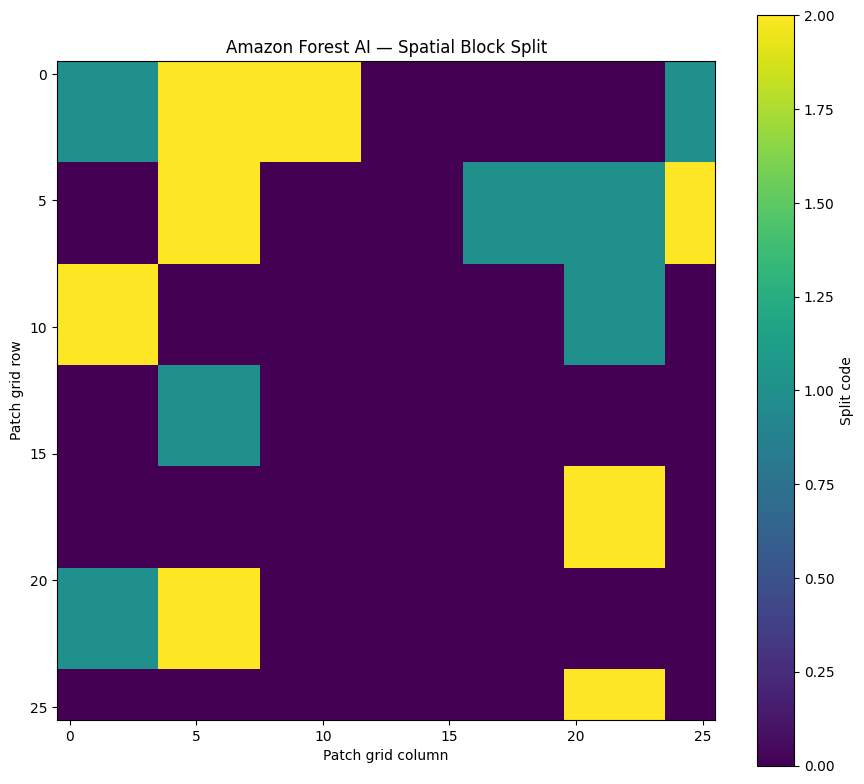

Saved map: /content/drive/MyDrive/Forest_AI_Project/Experiment_Results/Amazon/Patches/Amazon_spatial_split_map.png
Existing split modified: NO


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PATCH_DIR = os.path.join(
    ROOT, "Experiment_Results", "Amazon", "Patches"
)

coords = np.load(
    os.path.join(PATCH_DIR, "Amazon_patch_coordinates.npy")
)
assignment = np.load(
    os.path.join(PATCH_DIR, "Amazon_spatial_split_assignments.npy")
)

split = assignment[:, 3].astype(int)

# Reconstruct the 26 x 26 patch grid.
grid = np.full((26, 26), -1, dtype=int)

for (r, c), s in zip(coords, split):
    grid[int(r // 128), int(c // 128)] = s

print("=== STAGE 3O: SPATIAL SPLIT MAP ===")
print("Grid shape:", grid.shape)
print("Codes: 0=train, 1=validation, 2=test, -1=unassigned")

plt.figure(figsize=(9, 8))
plt.imshow(grid, interpolation="nearest")
plt.title("Amazon Forest AI — Spatial Block Split")
plt.xlabel("Patch grid column")
plt.ylabel("Patch grid row")
plt.colorbar(label="Split code")
plt.tight_layout()

out_path = os.path.join(PATCH_DIR, "Amazon_spatial_split_map.png")
plt.savefig(out_path, dpi=180, bbox_inches="tight")
plt.show()

print("Saved map:", out_path)
print("Existing split modified: NO")

In [ ]:
import os
import numpy as np

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PATCH_DIR = os.path.join(
    ROOT, "Experiment_Results", "Amazon", "Patches"
)

coords = np.load(
    os.path.join(PATCH_DIR, "Amazon_patch_coordinates.npy")
)

patch_rows = coords[:, 0] // 128
patch_cols = coords[:, 1] // 128

# Contiguous west-to-east split; diagnostic only.
# Columns 0–17: train, 18–21: validation, 22–25: test.
region_split = np.where(
    patch_cols < 18, 0,
    np.where(patch_cols < 22, 1, 2)
)

print("=== STAGE 3P: CONTIGUOUS REGION DIAGNOSTIC ===")
for code, name in [(0, "train"), (1, "validation"), (2, "test")]:
    mask = region_split == code
    print(f"\n{name.upper()}")
    print("Patches:", int(mask.sum()))
    print("Grid columns:",
          int(patch_cols[mask].min()),
          "to",
          int(patch_cols[mask].max()))

grid = np.full((26, 26), -1, dtype=int)
for r, c, s in zip(patch_rows, patch_cols, region_split):
    grid[int(r), int(c)] = int(s)

print("\nRegion grid (each row):")
for row in grid:
    print(" ".join(map(str, row)))

print("\nExisting split modified: NO")
print("New split saved: NO")

=== STAGE 3P: CONTIGUOUS REGION DIAGNOSTIC ===

TRAIN
Patches: 468
Grid columns: 0 to 17

VALIDATION
Patches: 104
Grid columns: 18 to 21

TEST
Patches: 104
Grid columns: 22 to 25

Region grid (each row):
0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 2 2 2 2
0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 2 2 2 2
0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 2 2 2 2
0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 2 2 2 2
0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 2 2 2 2
0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 2 2 2 2
0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 2 2 2 2
0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 2 2 2 2
0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 2 2 2 2
0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 2 2 2 2
0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 2 2 2 2
0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 2 2 2 2
0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 2 2 2 2
0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 2 2 2 2
0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 2 2 2 2
0 0 0 0 0 0 0 0 

In [ ]:
import os
import numpy as np

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PATCH_DIR = os.path.join(
    ROOT, "Experiment_Results", "Amazon", "Patches"
)

coords = np.load(
    os.path.join(PATCH_DIR, "Amazon_patch_coordinates.npy")
)
stats = np.load(
    os.path.join(PATCH_DIR, "Amazon_patch_label_stats.npy")
)

cols = coords[:, 1] // 128

regions = {
    "train": cols < 18,
    "validation": (cols >= 18) & (cols < 22),
    "test": cols >= 22
}

print("=== STAGE 3Q: CONTIGUOUS SPLIT LABEL AUDIT ===")

for name, mask in regions.items():
    total_pixels = int(stats[mask, 3].sum())
    loss_pixels = int(stats[mask, 4].sum())

    print(f"\n{name.upper()}")
    print("Patches:", int(mask.sum()))
    print("Patches with recorded loss:",
          int(np.sum(stats[mask, 4] > 0)))
    print("Patches without recorded loss:",
          int(np.sum(stats[mask, 4] == 0)))
    print("Nonzero-label pixels:", loss_pixels)
    print("Total pixels:", total_pixels)
    print("Nonzero-label prevalence:",
          round(100 * loss_pixels / total_pixels, 4), "%")

print("\nExisting assignments modified: NO")
print("Contiguous split saved: NO")

=== STAGE 3Q: CONTIGUOUS SPLIT LABEL AUDIT ===

TRAIN
Patches: 468
Patches with recorded loss: 309
Patches without recorded loss: 159
Nonzero-label pixels: 1127790
Total pixels: 7667712
Nonzero-label prevalence: 14.7083 %

VALIDATION
Patches: 104
Patches with recorded loss: 37
Patches without recorded loss: 67
Nonzero-label pixels: 257844
Total pixels: 1703936
Nonzero-label prevalence: 15.1323 %

TEST
Patches: 104
Patches with recorded loss: 36
Patches without recorded loss: 68
Nonzero-label pixels: 166167
Total pixels: 1703936
Nonzero-label prevalence: 9.752 %

Existing assignments modified: NO
Contiguous split saved: NO


In [ ]:
import os
import numpy as np

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PATCH_DIR = os.path.join(
    ROOT, "Experiment_Results", "Amazon", "Patches"
)

coords = np.load(
    os.path.join(PATCH_DIR, "Amazon_patch_coordinates.npy")
)

cols = coords[:, 1] // 128

# Codes: 0=train, 1=validation, 2=test
split_codes = np.where(
    cols < 18, 0,
    np.where(cols < 22, 1, 2)
).astype(np.uint8)

out_path = os.path.join(
    PATCH_DIR, "Amazon_contiguous_spatial_split.npy"
)

# Columns: row, col, split code
saved = np.column_stack([
    coords[:, 0],
    coords[:, 1],
    split_codes
]).astype(np.int32)

np.save(out_path, saved)

print("=== STAGE 3R: CONTIGUOUS SPLIT SAVED ===")
print("Saved path:", out_path)
print("Assignment shape:", saved.shape)
print("Codes: 0=train, 1=validation, 2=test")

for code, name in [(0, "train"), (1, "validation"), (2, "test")]:
    print(name, "patches:", int(np.sum(split_codes == code)))

print("Original block split preserved: YES")
print("Feature tensors extracted: NO")
print("Model training started: NO")

=== STAGE 3R: CONTIGUOUS SPLIT SAVED ===
Saved path: /content/drive/MyDrive/Forest_AI_Project/Experiment_Results/Amazon/Patches/Amazon_contiguous_spatial_split.npy
Assignment shape: (676, 3)
Codes: 0=train, 1=validation, 2=test
train patches: 468
validation patches: 104
test patches: 104
Original block split preserved: YES
Feature tensors extracted: NO
Model training started: NO


In [ ]:
import os
import numpy as np

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PATCH_DIR = os.path.join(
    ROOT, "Experiment_Results", "Amazon", "Patches"
)

coords = np.load(
    os.path.join(PATCH_DIR, "Amazon_patch_coordinates.npy")
)
saved = np.load(
    os.path.join(PATCH_DIR, "Amazon_contiguous_spatial_split.npy")
)

print("=== STAGE 3S: SAVED SPLIT INTEGRITY CHECK ===")
print("Original coordinates shape:", coords.shape)
print("Saved assignment shape:", saved.shape)

saved_coords = saved[:, :2]
split_codes = saved[:, 2]

print("Coordinates match original order:",
      bool(np.array_equal(coords, saved_coords)))
print("Unique saved coordinates:",
      len(np.unique(saved_coords, axis=0)))
print("Valid split codes:",
      bool(np.isin(split_codes, [0, 1, 2]).all()))
print("Missing assignments:", int(len(coords) - len(saved)))
print("Duplicate assignments:",
      int(len(saved) - len(np.unique(saved_coords, axis=0))))

for code, name in [(0, "train"), (1, "validation"), (2, "test")]:
    print(f"{name.title()} patches:", int(np.sum(split_codes == code)))

print("Integrity check complete.")
print("Feature tensors extracted: NO")
print("Model training started: NO")

=== STAGE 3S: SAVED SPLIT INTEGRITY CHECK ===
Original coordinates shape: (676, 2)
Saved assignment shape: (676, 3)
Coordinates match original order: True
Unique saved coordinates: 676
Valid split codes: True
Missing assignments: 0
Duplicate assignments: 0
Train patches: 468
Validation patches: 104
Test patches: 104
Integrity check complete.
Feature tensors extracted: NO
Model training started: NO


In [ ]:
import os
import numpy as np
import rasterio

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PREP = os.path.join(ROOT, "Experiment_Results", "Amazon", "Preprocessed")

print("=== STAGE 4B: FEATURE GRID VALIDATION ===")

feature_years = range(2019, 2026)
target_path = os.path.join(
    PREP, "Amazon_detection_target_provisional.tif"
)

with rasterio.open(target_path) as target:
    target_shape = (target.height, target.width)
    target_transform = target.transform
    target_crs = target.crs

print("Target shape:", target_shape)
print("Target CRS:", target_crs)

all_pass = True

for year in feature_years:
    path = os.path.join(PREP, f"Amazon_features_{year}.tif")

    if not os.path.exists(path):
        print(f"{year}: FAIL — missing file")
        all_pass = False
        continue

    with rasterio.open(path) as src:
        same_shape = (src.height, src.width) == target_shape
        same_transform = src.transform == target_transform
        same_crs = src.crs == target_crs
        correct_bands = src.count == 11

        passed = (
            same_shape and same_transform
            and same_crs and correct_bands
        )
        all_pass &= passed

        print(
            f"{year}: {'PASS' if passed else 'FAIL'} | "
            f"bands={src.count}, shape={(src.height, src.width)}, "
            f"same_transform={same_transform}, same_crs={same_crs}"
        )

print("\nOverall grid validation:", "PASS" if all_pass else "FAIL")
print("Feature tensors extracted: NO")
print("Training started: NO")

=== STAGE 4B: FEATURE GRID VALIDATION ===
Target shape: (3340, 3341)
Target CRS: EPSG:4326
2019: PASS | bands=11, shape=(3340, 3341), same_transform=True, same_crs=True
2020: PASS | bands=11, shape=(3340, 3341), same_transform=True, same_crs=True
2021: PASS | bands=11, shape=(3340, 3341), same_transform=True, same_crs=True
2022: PASS | bands=11, shape=(3340, 3341), same_transform=True, same_crs=True
2023: PASS | bands=11, shape=(3340, 3341), same_transform=True, same_crs=True
2024: PASS | bands=11, shape=(3340, 3341), same_transform=True, same_crs=True
2025: PASS | bands=11, shape=(3340, 3341), same_transform=True, same_crs=True

Overall grid validation: PASS
Feature tensors extracted: NO
Training started: NO


In [ ]:
import os
import numpy as np

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
CLAHE_DIR = os.path.join(
    ROOT, "Experiment_Results", "Amazon", "CLAHE"
)

print("=== STAGE 4C: CLAHE SAMPLE AUDIT ===")

for name in os.listdir(CLAHE_DIR):
    path = os.path.join(CLAHE_DIR, name)

    if not os.path.isfile(path):
        continue

    print(f"\nFile: {name}")
    print("Size (KB):", round(os.path.getsize(path) / 1024, 2))

    if name.endswith(".npz"):
        with np.load(path) as data:
            print("Stored arrays:", data.files)

            for key in data.files:
                arr = data[key]
                print(
                    f"  {key}: shape={arr.shape}, "
                    f"dtype={arr.dtype}, "
                    f"min={np.nanmin(arr):.4f}, "
                    f"max={np.nanmax(arr):.4f}"
                )

print("\nFull-resolution model inputs CLAHE-processed: NO")
print("Existing files modified: NO")

=== STAGE 4C: CLAHE SAMPLE AUDIT ===

File: CLAHE_2020_sample_comparison.png
Size (KB): 2812.34

File: Amazon_CLAHE_sample_2020.npz
Size (KB): 1507.02
Stored arrays: ['original', 'enhanced']
  original: shape=(512, 512, 3), dtype=uint8, min=0.0000, max=255.0000
  enhanced: shape=(512, 512, 3), dtype=uint8, min=0.0000, max=255.0000

File: Amazon_CLAHE_comparison.png
Size (KB): 3963.74

Full-resolution model inputs CLAHE-processed: NO
Existing files modified: NO


In [ ]:
import os
import numpy as np
import rasterio

ROOT = "/content/drive/MyDrive/Forest_AI_Project"

PREP = os.path.join(
    ROOT, "Experiment_Results", "Amazon", "Preprocessed"
)

PATCH_DIR = os.path.join(
    ROOT, "Experiment_Results", "Amazon", "Patches"
)

print("=== STAGE 4E: PREPROCESSING READINESS AUDIT ===")

feature_ok = True

for year in range(2019, 2026):
    path = os.path.join(PREP, f"Amazon_features_{year}.tif")

    if not os.path.exists(path):
        print(f"{year}: MISSING")
        feature_ok = False
        continue

    with rasterio.open(path) as src:
        print(
            f"{year}: bands={src.count}, "
            f"shape=({src.height}, {src.width}), "
            f"CRS={src.crs}"
        )

        if src.count != 11 or (src.height, src.width) != (3340, 3341):
            feature_ok = False

target_path = os.path.join(
    PREP, "Amazon_detection_target_provisional.tif"
)

split_path = os.path.join(
    PATCH_DIR, "Amazon_contiguous_spatial_split.npy"
)

print("\nProvisional target exists:", os.path.exists(target_path))
print("Contiguous split exists:", os.path.exists(split_path))

if os.path.exists(target_path):
    with rasterio.open(target_path) as src:
        print(
            "Target:",
            f"bands={src.count},",
            f"shape=({src.height}, {src.width}),",
            f"dtype={src.dtypes[0]}"
        )

if os.path.exists(split_path):
    split = np.load(split_path)
    print("Split array shape:", split.shape)
    print("Split codes/counts:", np.unique(split[:, 2], return_counts=True))

print("\nAll yearly feature rasters pass basic checks:", feature_ok)
print("No files modified; no model training started.")

=== STAGE 4E: PREPROCESSING READINESS AUDIT ===
2019: bands=11, shape=(3340, 3341), CRS=EPSG:4326
2020: bands=11, shape=(3340, 3341), CRS=EPSG:4326
2021: bands=11, shape=(3340, 3341), CRS=EPSG:4326
2022: bands=11, shape=(3340, 3341), CRS=EPSG:4326
2023: bands=11, shape=(3340, 3341), CRS=EPSG:4326
2024: bands=11, shape=(3340, 3341), CRS=EPSG:4326
2025: bands=11, shape=(3340, 3341), CRS=EPSG:4326

Provisional target exists: True
Contiguous split exists: True
Target: bands=1, shape=(3340, 3341), dtype=uint8
Split array shape: (676, 3)
Split codes/counts: (array([0, 1, 2], dtype=int32), array([468, 104, 104]))

All yearly feature rasters pass basic checks: True
No files modified; no model training started.


In [ ]:
import os
import numpy as np
import rasterio

ROOT = "/content/drive/MyDrive/Forest_AI_Project"

files = {
    "Provisional detection target": os.path.join(
        ROOT, "Experiment_Results", "Amazon", "Preprocessed",
        "Amazon_detection_target_provisional.tif"
    ),
    "Aligned GFW in Preprocessed": os.path.join(
        ROOT, "Experiment_Results", "Amazon", "Preprocessed",
        "Amazon_GFW_aligned.tif"
    ),
    "Aligned GFW in main Preprocessed": os.path.join(
        ROOT, "Preprocessed", "Amazon_GFW_lossyear_aligned_10m.tif"
    ),
}

print("=== STAGE 4F: GFW TARGET METADATA AUDIT ===")

for label, path in files.items():
    print(f"\n--- {label} ---")
    print("Exists:", os.path.exists(path))

    if not os.path.exists(path):
        continue

    with rasterio.open(path) as src:
        print("Shape:", (src.height, src.width))
        print("Dtype:", src.dtypes)
        print("CRS:", src.crs)
        print("Transform:", src.transform)
        print("Nodata:", src.nodata)
        print("Dataset tags:", src.tags())
        print("Band 1 tags:", src.tags(1))
        print("Band 1 description:", src.descriptions[0])

        arr = src.read(1)
        values, counts = np.unique(arr, return_counts=True)

        print("Unique values:", len(values))
        print("Value counts:")
        for value, count in zip(values, counts):
            print(f"  {value}: {count:,}")

print("\nNo files modified.")

=== STAGE 4F: GFW TARGET METADATA AUDIT ===

--- Provisional detection target ---
Exists: True
Shape: (3340, 3341)
Dtype: ('uint8',)
CRS: EPSG:4326
Transform: | 0.00, 0.00,-64.70|
| 0.00,-0.00,-7.20|
| 0.00, 0.00, 1.00|
Nodata: None
Dataset tags: {'status': 'PROVISIONAL - source version and temporal interpretation unverified', 'target_definition': '1=nonzero GFW loss-year code; 0=code 0', 'AREA_OR_POINT': 'Area'}
Band 1 tags: {}
Band 1 description: Provisional recorded forest-loss indicator
Unique values: 2
Value counts:
  0: 9,599,414
  1: 1,559,526

--- Aligned GFW in Preprocessed ---
Exists: True
Shape: (3340, 3341)
Dtype: ('uint8',)
CRS: EPSG:4326
Transform: | 0.00, 0.00,-64.70|
| 0.00,-0.00,-7.20|
| 0.00, 0.00, 1.00|
Nodata: 255.0
Dataset tags: {'AREA_OR_POINT': 'Area'}
Band 1 tags: {}
Band 1 description: None
Unique values: 25
Value counts:
  0: 9,599,414
  1: 26,685
  2: 13,848
  3: 20,208
  4: 11,262
  5: 23,406
  6: 28,095
  7: 40,416
  8: 21,411
  9: 16,038
  10: 60,918
  11:

In [ ]:
import os

ROOT = "/content/drive/MyDrive/Forest_AI_Project"

print("=== STAGE 4G: GFW SOURCE PROVENANCE SEARCH ===")

terms = ("gfw", "lossyear", "tree_cover_loss", "hansen", "metadata")

for current_root, dirs, files in os.walk(ROOT):
    # Avoid searching large data folders recursively.
    dirs[:] = [
        d for d in dirs
        if d not in {"Patches", "CLAHE", "Checkpoints", "Results"}
    ]

    for name in files:
        lower = name.lower()
        if any(term in lower for term in terms):
            path = os.path.join(current_root, name)
            print(path)

print("\nSearch complete. No files modified.")

=== STAGE 4G: GFW SOURCE PROVENANCE SEARCH ===
/content/drive/MyDrive/Forest_AI_Project/Kalimantan_GFW_lossyear.tif
/content/drive/MyDrive/Forest_AI_Project/GFW/Lunglei_Mizoram_GFW_lossyear.tif
/content/drive/MyDrive/Forest_AI_Project/Preprocessed/Lunglei_GFW_lossyear_aligned_10m.tif
/content/drive/MyDrive/Forest_AI_Project/Preprocessed/Amazon_GFW_lossyear_aligned_10m.tif
/content/drive/MyDrive/Forest_AI_Project/Congo_Forest_AI/Congo_GFW_lossyear.tif
/content/drive/MyDrive/Forest_AI_Project/Experiment_Results/Amazon/Preprocessed/Amazon_GFW_aligned.tif
/content/drive/MyDrive/Forest_AI_Project/Experiment_Results/Amazon/Hotspots/Amazon_GFW_hotspots_initial.tif
/content/drive/MyDrive/Forest_AI_Project/Experiment_Results/Amazon/Hotspots/Amazon_GFW_hotspots_preview.png

Search complete. No files modified.


In [ ]:
import os
import numpy as np
import rasterio

ROOT = "/content/drive/MyDrive/Forest_AI_Project"

paths = [
    os.path.join(ROOT, "Kalimantan_GFW_lossyear.tif"),
    os.path.join(ROOT, "Congo_Forest_AI", "Congo_GFW_lossyear.tif"),
    os.path.join(ROOT, "GFW", "Lunglei_Mizoram_GFW_lossyear.tif"),
]

print("=== STAGE 4H: GFW RASTER COMPARISON ===")

for path in paths:
    print(f"\nFile: {path}")

    if not os.path.exists(path):
        print("MISSING")
        continue

    with rasterio.open(path) as src:
        print("Shape:", (src.height, src.width))
        print("CRS:", src.crs)
        print("Dtype:", src.dtypes[0])
        print("Nodata:", src.nodata)
        print("Dataset tags:", src.tags())
        print("Band tags:", src.tags(1))
        print("Description:", src.descriptions[0])

        values, counts = np.unique(src.read(1), return_counts=True)
        print("Unique values:", values.tolist())
        print("Pixel counts:", counts.tolist())

print("\nNo files modified.")

=== STAGE 4H: GFW RASTER COMPARISON ===

File: /content/drive/MyDrive/Forest_AI_Project/Kalimantan_GFW_lossyear.tif
Shape: (1114, 1114)
CRS: EPSG:4326
Dtype: uint8
Nodata: None
Dataset tags: {'AREA_OR_POINT': 'Area'}
Band tags: {}
Description: lossyear
Unique values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25]
Pixel counts: [1093084, 105, 68, 7202, 433, 480, 66, 8664, 1631, 492, 1622, 1141, 3855, 882, 16065, 8648, 89761, 601, 729, 1009, 343, 277, 466, 2953, 209, 210]

File: /content/drive/MyDrive/Forest_AI_Project/Congo_Forest_AI/Congo_GFW_lossyear.tif
Shape: (1114, 1114)
CRS: EPSG:4326
Dtype: uint8
Nodata: None
Dataset tags: {'AREA_OR_POINT': 'Area'}
Band tags: {}
Description: lossyear
Unique values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25]
Pixel counts: [1087165, 4396, 2586, 1398, 3147, 1416, 4281, 206, 1086, 4881, 11759, 251, 2767, 13030, 8967, 6785, 12972, 13079, 9680, 9309, 697

In [ ]:
import os

filename = "Amazon_GFW_lossyear.tif"
matches = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    if filename in files:
        matches.append(os.path.join(root, filename))

print("=== ORIGINAL AMAZON GFW FILE SEARCH ===")

if matches:
    for path in matches:
        print("FOUND:", path)
else:
    print("Original file not found in MyDrive.")
    print("It may exist only in 'Shared with me' or a shared-drive mount.")

=== ORIGINAL AMAZON GFW FILE SEARCH ===
Original file not found in MyDrive.
It may exist only in 'Shared with me' or a shared-drive mount.


In [ ]:
import os

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
filename = "Amazon_GFW_lossyear.tif"

print("=== CHECK ORIGINAL GFW FILE ===")

for current_root, dirs, files in os.walk(ROOT):
    if filename in files:
        path = os.path.join(current_root, filename)
        print("FOUND:", path)
        print("File size (MB):", round(os.path.getsize(path) / (1024**2), 2))

if not any(
    filename in files
    for _, _, files in os.walk(ROOT)
):
    print("NOT FOUND under MyDrive/Forest_AI_Project")
    print("Check that Google Drive has finished syncing and that the shortcut is accessible.")

=== CHECK ORIGINAL GFW FILE ===
NOT FOUND under MyDrive/Forest_AI_Project
Check that Google Drive has finished syncing and that the shortcut is accessible.


In [ ]:
import os

paths = [
    "/content/drive/MyDrive/Forest_AI_Project/Amazon_Forest_AI/Amazon_GFW_lossyear.tif",
    "/content/drive/MyDrive/Amazon_Forest_AI/Amazon_GFW_lossyear.tif",
]

for path in paths:
    print("\nPath:", path)
    print("Exists:", os.path.exists(path))

    if os.path.isfile(path):
        print("Size (MB):", round(os.path.getsize(path) / (1024**2), 2))



Path: /content/drive/MyDrive/Forest_AI_Project/Amazon_Forest_AI/Amazon_GFW_lossyear.tif
Exists: True
Size (MB): 0.07

Path: /content/drive/MyDrive/Amazon_Forest_AI/Amazon_GFW_lossyear.tif
Exists: False


In [ ]:
import os
import numpy as np
import rasterio

original = (
    "/content/drive/MyDrive/Forest_AI_Project/"
    "Amazon_Forest_AI/Amazon_GFW_lossyear.tif"
)

aligned = (
    "/content/drive/MyDrive/Forest_AI_Project/"
    "Experiment_Results/Amazon/Preprocessed/"
    "Amazon_GFW_aligned.tif"
)

for label, path in [("ORIGINAL", original), ("ALIGNED", aligned)]:
    print(f"\n=== {label} GFW ===")
    print("Path:", path)
    print("Size (MB):", round(os.path.getsize(path) / (1024**2), 4))

    with rasterio.open(path) as src:
        print("Dimensions:", src.width, "x", src.height)
        print("Bands:", src.count)
        print("Dtype:", src.dtypes)
        print("CRS:", src.crs)
        print("Transform:", src.transform)
        print("Nodata:", src.nodata)
        print("Tags:", src.tags())
        print("Band descriptions:", src.descriptions)

        arr = src.read(1)
        values, counts = np.unique(arr, return_counts=True)
        print("Unique values:", values.tolist())
        print("Pixel counts:", counts.tolist())

print("\nNo files modified.")


=== ORIGINAL GFW ===
Path: /content/drive/MyDrive/Forest_AI_Project/Amazon_Forest_AI/Amazon_GFW_lossyear.tif
Size (MB): 0.0715
Dimensions: 1115 x 1114
Bands: 1
Dtype: ('uint8',)
CRS: EPSG:4326
Transform: | 0.00, 0.00,-64.70|
| 0.00,-0.00,-7.20|
| 0.00, 0.00, 1.00|
Nodata: None
Tags: {'AREA_OR_POINT': 'Area'}
Band descriptions: ('lossyear',)
Unique values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
Pixel counts: [1068442, 2975, 1546, 2246, 1252, 2604, 3135, 4494, 2383, 1784, 6820, 3791, 9637, 4855, 6019, 7230, 6577, 9923, 9096, 6780, 10798, 18877, 13839, 8707, 28300]

=== ALIGNED GFW ===
Path: /content/drive/MyDrive/Forest_AI_Project/Experiment_Results/Amazon/Preprocessed/Amazon_GFW_aligned.tif
Size (MB): 0.107
Dimensions: 3341 x 3340
Bands: 1
Dtype: ('uint8',)
CRS: EPSG:4326
Transform: | 0.00, 0.00,-64.70|
| 0.00,-0.00,-7.20|
| 0.00, 0.00, 1.00|
Nodata: 255.0
Tags: {'AREA_OR_POINT': 'Area'}
Band descriptions: (None,)
Unique values: [0, 1

In [ ]:
import os
import numpy as np
import rasterio

original = (
    "/content/drive/MyDrive/Forest_AI_Project/"
    "Amazon_Forest_AI/Amazon_GFW_lossyear.tif"
)
aligned = (
    "/content/drive/MyDrive/Forest_AI_Project/"
    "Experiment_Results/Amazon/Preprocessed/"
    "Amazon_GFW_aligned.tif"
)

print("=== STAGE 4J: ALIGNMENT VALIDATION ===")

with rasterio.open(original) as src, rasterio.open(aligned) as dst:
    print("Original resolution:", src.res)
    print("Aligned resolution:", dst.res)
    print("Original bounds:", src.bounds)
    print("Aligned bounds:", dst.bounds)
    print("Resolution ratio:", (
        abs(src.res[0] / dst.res[0]),
        abs(src.res[1] / dst.res[1])
    ))

    original_values = set(np.unique(src.read(1)).tolist())
    aligned_values = set(np.unique(dst.read(1)).tolist())

    print("\nOriginal codes:", sorted(original_values))
    print("Aligned codes:", sorted(aligned_values))
    print("Aligned contains only original codes:",
          aligned_values.issubset(original_values))

    print("\nOriginal transform:", src.transform)
    print("Aligned transform:", dst.transform)

print("\nNo files modified.")

=== STAGE 4J: ALIGNMENT VALIDATION ===
Original resolution: (0.00026949458523585647, 0.00026949458523585647)
Aligned resolution: (8.983152841195215e-05, 8.983152841195215e-05)
Original bounds: BoundingBox(left=-64.70024513644688, bottom=-7.500040923548349, right=-64.3997586739089, top=-7.199823955595605)
Aligned bounds: BoundingBox(left=-64.7000803603676, bottom=-7.500034307113886, right=-64.39995322394326, top=-7.199997002217965)
Resolution ratio: (3.0000000000000004, 3.0000000000000004)

Original codes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
Aligned codes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
Aligned contains only original codes: True

Original transform: | 0.00, 0.00,-64.70|
| 0.00,-0.00,-7.20|
| 0.00, 0.00, 1.00|
Aligned transform: | 0.00, 0.00,-64.70|
| 0.00,-0.00,-7.20|
| 0.00, 0.00, 1.00|

No files modified.


In [ ]:
import numpy as np
import rasterio
from rasterio.warp import reproject, Resampling

original = (
    "/content/drive/MyDrive/Forest_AI_Project/"
    "Amazon_Forest_AI/Amazon_GFW_lossyear.tif"
)
aligned = (
    "/content/drive/MyDrive/Forest_AI_Project/"
    "Experiment_Results/Amazon/Preprocessed/"
    "Amazon_GFW_aligned.tif"
)
feature = (
    "/content/drive/MyDrive/Forest_AI_Project/"
    "Experiment_Results/Amazon/Preprocessed/"
    "Amazon_features_2020.tif"
)

print("=== STAGE 4K: INDEPENDENT ALIGNMENT CHECK ===")

with rasterio.open(original) as src, \
     rasterio.open(aligned) as saved, \
     rasterio.open(feature) as ref:

    source = src.read(1)
    saved_arr = saved.read(1)

    regenerated = np.zeros((ref.height, ref.width), dtype=np.uint8)

    reproject(
        source=source,
        destination=regenerated,
        src_transform=src.transform,
        src_crs=src.crs,
        dst_transform=ref.transform,
        dst_crs=ref.crs,
        resampling=Resampling.nearest,
    )

    print("Shapes match:", regenerated.shape == saved_arr.shape)
    print("Saved aligned equals independent nearest-neighbor result:",
          np.array_equal(saved_arr, regenerated))

    mismatch = saved_arr != regenerated
    print("Mismatched pixels:", int(mismatch.sum()))
    print("Mismatch percentage:", round(100 * mismatch.mean(), 6), "%")

    print("Independent codes:", np.unique(regenerated).tolist())
    print("Saved codes:", np.unique(saved_arr).tolist())

print("\nNo files modified.")

=== STAGE 4K: INDEPENDENT ALIGNMENT CHECK ===
Shapes match: True
Saved aligned equals independent nearest-neighbor result: True
Mismatched pixels: 0
Mismatch percentage: 0.0 %
Independent codes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
Saved codes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]

No files modified.


In [ ]:
import hashlib
import rasterio

path = (
    "/content/drive/MyDrive/Forest_AI_Project/"
    "Amazon_Forest_AI/Amazon_GFW_lossyear.tif"
)

print("=== STAGE 4L: SOURCE IDENTITY CHECK ===")

with rasterio.open(path) as src:
    print("Band description:", src.descriptions[0])
    print("Dataset tags:", src.tags())
    print("Band tags:", src.tags(1))
    print("Dimensions:", src.width, "x", src.height)
    print("Bounds:", src.bounds)
    print("CRS:", src.crs)

digest = hashlib.sha256()
with open(path, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        digest.update(chunk)

print("SHA-256:", digest.hexdigest())
print("\nNo files modified.")

=== STAGE 4L: SOURCE IDENTITY CHECK ===
Band description: lossyear
Dataset tags: {'AREA_OR_POINT': 'Area'}
Band tags: {}
Dimensions: 1115 x 1114
Bounds: BoundingBox(left=-64.70024513644688, bottom=-7.500040923548349, right=-64.3997586739089, top=-7.199823955595605)
CRS: EPSG:4326
SHA-256: bd4ebf5fa055a5bb9c414b6f8a168dc01c0189acb8c6efc917d27da0d2282b42

No files modified.


In [ ]:
import os
import numpy as np
import rasterio

ROOT = "/content/drive/MyDrive/Forest_AI_Project"

gfw_path = os.path.join(
    ROOT, "Experiment_Results", "Amazon",
    "Preprocessed", "Amazon_GFW_aligned.tif"
)

print("=== STAGE 4M: YEAR-SPECIFIC LOSS LABEL AUDIT ===")

with rasterio.open(gfw_path) as src:
    gfw = src.read(1)

    for year in range(2019, 2026):
        code = year - 2000
        positive = int(np.count_nonzero(gfw == code))
        total = gfw.size
        percentage = 100 * positive / total

        print(
            f"{year}: GFW code={code}, "
            f"loss pixels={positive:,}, "
            f"share of raster={percentage:.5f}%"
        )

    print("\nRaster shape:", gfw.shape)
    print("Observed codes:", np.unique(gfw).tolist())

print("\nNo files modified.")

=== STAGE 4M: YEAR-SPECIFIC LOSS LABEL AUDIT ===
2019: GFW code=19, loss pixels=60,966, share of raster=0.54634%
2020: GFW code=20, loss pixels=97,122, share of raster=0.87035%
2021: GFW code=21, loss pixels=169,737, share of raster=1.52109%
2022: GFW code=22, loss pixels=124,047, share of raster=1.11164%
2023: GFW code=23, loss pixels=78,225, share of raster=0.70101%
2024: GFW code=24, loss pixels=254,106, share of raster=2.27715%
2025: GFW code=25, loss pixels=0, share of raster=0.00000%

Raster shape: (3340, 3341)
Observed codes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]

No files modified.


In [ ]:
import os
import numpy as np
import rasterio

ROOT = "/content/drive/MyDrive/Forest_AI_Project"

PREP = os.path.join(
    ROOT, "Experiment_Results", "Amazon", "Preprocessed"
)

GFW_PATH = os.path.join(PREP, "Amazon_GFW_aligned.tif")

print("=== STAGE 4N: YEAR-SPECIFIC TARGET CREATION ===")

with rasterio.open(GFW_PATH) as src:
    gfw = src.read(1)
    profile = src.profile.copy()

for year in range(2019, 2025):
    code = year - 2000
    target = (gfw == code).astype(np.uint8)

    output_path = os.path.join(
        PREP, f"Amazon_detection_target_{year}_provisional.tif"
    )

    out_profile = profile.copy()
    out_profile.update(
        driver="GTiff",
        count=1,
        dtype="uint8",
        nodata=None,
        compress="deflate"
    )

    with rasterio.open(output_path, "w", **out_profile) as dst:
        dst.write(target, 1)
        dst.set_band_description(
            1, f"Provisional forest loss detected in {year}"
        )
        dst.update_tags(
            status="PROVISIONAL - GFW source version unverified",
            target_definition=f"1=lossyear code {code}; 0=all other codes",
            target_year=str(year),
            source="Amazon_GFW_aligned.tif"
        )

    positives = int(target.sum())
    print(
        f"{year}: code={code}, positive pixels={positives:,}, "
        f"negative pixels={target.size - positives:,}"
    )
    print("  Saved:", output_path)

print("\n2025 excluded from supervised target creation.")
print("Original GFW and existing provisional target unchanged.")

=== STAGE 4N: YEAR-SPECIFIC TARGET CREATION ===
2019: code=19, positive pixels=60,966, negative pixels=11,097,974
  Saved: /content/drive/MyDrive/Forest_AI_Project/Experiment_Results/Amazon/Preprocessed/Amazon_detection_target_2019_provisional.tif
2020: code=20, positive pixels=97,122, negative pixels=11,061,818
  Saved: /content/drive/MyDrive/Forest_AI_Project/Experiment_Results/Amazon/Preprocessed/Amazon_detection_target_2020_provisional.tif
2021: code=21, positive pixels=169,737, negative pixels=10,989,203
  Saved: /content/drive/MyDrive/Forest_AI_Project/Experiment_Results/Amazon/Preprocessed/Amazon_detection_target_2021_provisional.tif
2022: code=22, positive pixels=124,047, negative pixels=11,034,893
  Saved: /content/drive/MyDrive/Forest_AI_Project/Experiment_Results/Amazon/Preprocessed/Amazon_detection_target_2022_provisional.tif
2023: code=23, positive pixels=78,225, negative pixels=11,080,715
  Saved: /content/drive/MyDrive/Forest_AI_Project/Experiment_Results/Amazon/Preproce

In [ ]:
import os
import numpy as np
import rasterio

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PREP = os.path.join(
    ROOT, "Experiment_Results", "Amazon", "Preprocessed"
)

print("=== STAGE 4O: TARGET VALIDATION ===")

all_pass = True

for year in range(2019, 2025):
    path = os.path.join(
        PREP, f"Amazon_detection_target_{year}_provisional.tif"
    )

    if not os.path.exists(path):
        print(f"{year}: FAIL — file missing")
        all_pass = False
        continue

    with rasterio.open(path) as src:
        arr = src.read(1)
        values = np.unique(arr).tolist()
        positive = int(np.count_nonzero(arr == 1))
        tags = src.tags()

        passed = (
            arr.shape == (3340, 3341)
            and values == [0, 1]
            and tags.get("target_year") == str(year)
        )

        print(
            f"{year}: {'PASS' if passed else 'FAIL'} | "
            f"shape={arr.shape} | values={values} | "
            f"positive={positive:,} | "
            f"metadata_year={tags.get('target_year')}"
        )

        all_pass &= passed

print("\nALL SIX TARGETS PASS:", all_pass)
print("No files modified.")

=== STAGE 4O: TARGET VALIDATION ===
2019: PASS | shape=(3340, 3341) | values=[0, 1] | positive=60,966 | metadata_year=2019
2020: PASS | shape=(3340, 3341) | values=[0, 1] | positive=97,122 | metadata_year=2020
2021: PASS | shape=(3340, 3341) | values=[0, 1] | positive=169,737 | metadata_year=2021
2022: PASS | shape=(3340, 3341) | values=[0, 1] | positive=124,047 | metadata_year=2022
2023: PASS | shape=(3340, 3341) | values=[0, 1] | positive=78,225 | metadata_year=2023
2024: PASS | shape=(3340, 3341) | values=[0, 1] | positive=254,106 | metadata_year=2024

ALL SIX TARGETS PASS: True
No files modified.


In [ ]:
import os
import numpy as np
import rasterio

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
BASE = os.path.join(ROOT, "Experiment_Results", "Amazon")
PREP = os.path.join(BASE, "Preprocessed")
PATCH_DIR = os.path.join(BASE, "Patches")

coords_path = os.path.join(PATCH_DIR, "Amazon_patch_coordinates.npy")
split_path = os.path.join(PATCH_DIR, "Amazon_contiguous_spatial_split.npy")
target_path = os.path.join(PREP, "Amazon_detection_target_2020_provisional.tif")

PATCH_SIZE = 128

print("=== STAGE 5A: SPATIAL SPLIT AND PATCH AUDIT ===")

coords = np.load(coords_path)
split = np.load(split_path)

print("Coordinates shape:", coords.shape)
print("Split shape:", split.shape)
print("Split codes/counts:", np.unique(split[:, 2], return_counts=True))

assert coords.shape == (676, 2), "Unexpected coordinate array shape"
assert split.shape == (676, 3), "Unexpected split array shape"
assert np.array_equal(coords, split[:, :2]), "Coordinate ordering mismatch"

with rasterio.open(target_path) as src:
    target = src.read(1)

split_names = {0: "TRAIN", 1: "VALIDATION", 2: "TEST"}

for code, name in split_names.items():
    rows = split[split[:, 2] == code, :2]
    positive_pixels = 0
    positive_patches = 0

    for row, col in rows:
        patch = target[row:row + PATCH_SIZE, col:col + PATCH_SIZE]
        positive_pixels += int(patch.sum())
        positive_patches += int(np.any(patch == 1))

    total_pixels = len(rows) * PATCH_SIZE * PATCH_SIZE

    print(
        f"{name}: patches={len(rows)}, "
        f"positive patches={positive_patches}, "
        f"positive pixels={positive_pixels:,}, "
        f"positive pixel share={100 * positive_pixels / total_pixels:.5f}%"
    )

print("\nAudit completed. No files modified.")

=== STAGE 5A: SPATIAL SPLIT AND PATCH AUDIT ===
Coordinates shape: (676, 2)
Split shape: (676, 3)
Split codes/counts: (array([0, 1, 2], dtype=int32), array([468, 104, 104]))
TRAIN: patches=468, positive patches=158, positive pixels=59,040, positive pixel share=0.76998%
VALIDATION: patches=104, positive patches=15, positive pixels=36,324, positive pixel share=2.13177%
TEST: patches=104, positive patches=7, positive pixels=1,596, positive pixel share=0.09367%

Audit completed. No files modified.


In [ ]:
import os
import numpy as np
import rasterio

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PREP = os.path.join(ROOT, "Experiment_Results", "Amazon", "Preprocessed")
PATCH_DIR = os.path.join(ROOT, "Experiment_Results", "Amazon", "Patches")

coords = np.load(os.path.join(PATCH_DIR, "Amazon_patch_coordinates.npy"))
split = np.load(os.path.join(PATCH_DIR, "Amazon_contiguous_spatial_split.npy"))

PATCH_SIZE = 128
names = {0: "TRAIN", 1: "VALIDATION", 2: "TEST"}

print("=== STAGE 5B: SIX-YEAR SPATIAL LABEL AUDIT ===")

for year in range(2019, 2025):
    path = os.path.join(
        PREP, f"Amazon_detection_target_{year}_provisional.tif"
    )

    with rasterio.open(path) as src:
        target = src.read(1)

    print(f"\nYEAR {year}")

    for code, name in names.items():
        positions = split[split[:, 2] == code, :2]
        positive_pixels = 0
        positive_patches = 0

        for row, col in positions:
            patch = target[row:row + PATCH_SIZE, col:col + PATCH_SIZE]
            positive_pixels += int(patch.sum())
            positive_patches += int(np.any(patch == 1))

        total_pixels = len(positions) * PATCH_SIZE**2

        print(
            f"{name}: patches={len(positions)}, "
            f"positive_patches={positive_patches}, "
            f"positive_pixels={positive_pixels:,}, "
            f"positive_share={100 * positive_pixels / total_pixels:.5f}%"
        )

print("\nAudit only; no files modified.")

=== STAGE 5B: SIX-YEAR SPATIAL LABEL AUDIT ===

YEAR 2019
TRAIN: patches=468, positive_patches=139, positive_pixels=27,810, positive_share=0.36269%
VALIDATION: patches=104, positive_patches=13, positive_pixels=26,319, positive_share=1.54460%
TEST: patches=104, positive_patches=8, positive_pixels=6,801, positive_share=0.39913%

YEAR 2020
TRAIN: patches=468, positive_patches=158, positive_pixels=59,040, positive_share=0.76998%
VALIDATION: patches=104, positive_patches=15, positive_pixels=36,324, positive_share=2.13177%
TEST: patches=104, positive_patches=7, positive_pixels=1,596, positive_share=0.09367%

YEAR 2021
TRAIN: patches=468, positive_patches=171, positive_pixels=129,600, positive_share=1.69020%
VALIDATION: patches=104, positive_patches=11, positive_pixels=34,095, positive_share=2.00096%
TEST: patches=104, positive_patches=3, positive_pixels=3,792, positive_share=0.22254%

YEAR 2022
TRAIN: patches=468, positive_patches=173, positive_pixels=112,179, positive_share=1.46300%
VALIDAT

In [ ]:
import os
import rasterio

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PREP = os.path.join(ROOT, "Experiment_Results", "Amazon", "Preprocessed")

print("=== STAGE 5C: YEARLY FEATURE-TARGET PAIR AUDIT ===")

all_pass = True

for year in range(2019, 2025):
    feature_path = os.path.join(PREP, f"Amazon_features_{year}.tif")
    target_path = os.path.join(
        PREP, f"Amazon_detection_target_{year}_provisional.tif"
    )

    with rasterio.open(feature_path) as x, rasterio.open(target_path) as y:
        same_grid = (
            x.width == y.width
            and x.height == y.height
            and x.crs == y.crs
            and x.transform == y.transform
        )

        passed = x.count == 11 and y.count == 1 and same_grid
        all_pass &= passed

        print(
            f"{year}: {'PASS' if passed else 'FAIL'} | "
            f"features={x.count} bands | target={y.count} band | "
            f"grid_match={same_grid}"
        )

print("\nALL YEARLY PAIRS PASS:", all_pass)
print("No files modified.")

=== STAGE 5C: YEARLY FEATURE-TARGET PAIR AUDIT ===
2019: PASS | features=11 bands | target=1 band | grid_match=True
2020: PASS | features=11 bands | target=1 band | grid_match=True
2021: PASS | features=11 bands | target=1 band | grid_match=True
2022: PASS | features=11 bands | target=1 band | grid_match=True
2023: PASS | features=11 bands | target=1 band | grid_match=True
2024: PASS | features=11 bands | target=1 band | grid_match=True

ALL YEARLY PAIRS PASS: True
No files modified.


In [ ]:
import os
import numpy as np
import rasterio

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
BASE = os.path.join(ROOT, "Experiment_Results", "Amazon")
PREP = os.path.join(BASE, "Preprocessed")
PATCH_DIR = os.path.join(BASE, "Patches")

PATCH_SIZE = 128

coords = np.load(os.path.join(PATCH_DIR, "Amazon_patch_coordinates.npy"))
split = np.load(os.path.join(PATCH_DIR, "Amazon_contiguous_spatial_split.npy"))

# Select the first training patch
train_indices = np.where(split[:, 2] == 0)[0]
idx = int(train_indices[0])
row, col = map(int, coords[idx])

print("=== STAGE 5D: SINGLE-PATCH EXTRACTION TEST ===")
print("Patch index:", idx)
print("Spatial position:", (row, col))
print("Partition code:", int(split[idx, 2]))

for year in range(2019, 2025):
    feature_path = os.path.join(PREP, f"Amazon_features_{year}.tif")
    target_path = os.path.join(
        PREP, f"Amazon_detection_target_{year}_provisional.tif"
    )

    with rasterio.open(feature_path) as src:
        X = src.read(
            window=((row, row + PATCH_SIZE), (col, col + PATCH_SIZE))
        )

    with rasterio.open(target_path) as src:
        Y = src.read(
            1,
            window=((row, row + PATCH_SIZE), (col, col + PATCH_SIZE))
        )

    print(
        f"{year}: X shape={X.shape}, dtype={X.dtype}, "
        f"range=({np.nanmin(X):.4f}, {np.nanmax(X):.4f}); "
        f"Y shape={Y.shape}, dtype={Y.dtype}, "
        f"labels={np.unique(Y).tolist()}, positives={int(Y.sum())}"
    )

print("\nDry run only: no patch dataset saved, no training started.")

=== STAGE 5D: SINGLE-PATCH EXTRACTION TEST ===
Patch index: 0
Spatial position: (0, 0)
Partition code: 0
2019: X shape=(11, 128, 128), dtype=float32, range=(0.0212, 0.9331); Y shape=(128, 128), dtype=uint8, labels=[0], positives=0
2020: X shape=(11, 128, 128), dtype=float32, range=(0.0183, 0.9359); Y shape=(128, 128), dtype=uint8, labels=[0], positives=0
2021: X shape=(11, 128, 128), dtype=float32, range=(0.0217, 0.9342); Y shape=(128, 128), dtype=uint8, labels=[0], positives=0
2022: X shape=(11, 128, 128), dtype=float32, range=(0.0204, 0.9404); Y shape=(128, 128), dtype=uint8, labels=[0, 1], positives=108
2023: X shape=(11, 128, 128), dtype=float32, range=(0.0176, 0.9432); Y shape=(128, 128), dtype=uint8, labels=[0, 1], positives=162
2024: X shape=(11, 128, 128), dtype=float32, range=(0.0185, 0.9414); Y shape=(128, 128), dtype=uint8, labels=[0], positives=0

Dry run only: no patch dataset saved, no training started.


In [ ]:
import os
import shutil
import numpy as np

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PATCH_DIR = os.path.join(ROOT, "Experiment_Results", "Amazon", "Patches")

coords = np.load(os.path.join(PATCH_DIR, "Amazon_patch_coordinates.npy"))

years = 6
patches = len(coords)
bands = 11
size = 128

feature_bytes = years * patches * bands * size * size * 4
label_bytes = years * patches * size * size * 1

print("=== STAGE 5E: STORAGE ESTIMATE ===")
print("Years:", years)
print("Patches per year:", patches)
print("Feature tensor shape if combined:", (years, patches, bands, size, size))
print("Label tensor shape if combined:", (years, patches, size, size))
print("Estimated feature storage (GB):", round(feature_bytes / 1e9, 3))
print("Estimated label storage (GB):", round(label_bytes / 1e9, 3))
print("Estimated total storage (GB):", round((feature_bytes + label_bytes) / 1e9, 3))

usage = shutil.disk_usage("/content")
print("Colab free disk space (GB):", round(usage.free / 1e9, 2))

print("No dataset allocated or files modified.")

=== STAGE 5E: STORAGE ESTIMATE ===
Years: 6
Patches per year: 676
Feature tensor shape if combined: (6, 676, 11, 128, 128)
Label tensor shape if combined: (6, 676, 128, 128)
Estimated feature storage (GB): 2.924
Estimated label storage (GB): 0.066
Estimated total storage (GB): 2.99
Colab free disk space (GB): 70.02
No dataset allocated or files modified.


In [ ]:
import os
import numpy as np
import rasterio

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
BASE = os.path.join(ROOT, "Experiment_Results", "Amazon")
PREP = os.path.join(BASE, "Preprocessed")
PATCH_DIR = os.path.join(BASE, "Patches")
OUTPUT_DIR = os.path.join(PATCH_DIR, "Yearly_Extracted")

os.makedirs(OUTPUT_DIR, exist_ok=True)

YEAR = 2019
PATCH_SIZE = 128

coords = np.load(os.path.join(PATCH_DIR, "Amazon_patch_coordinates.npy"))
split = np.load(os.path.join(PATCH_DIR, "Amazon_contiguous_spatial_split.npy"))

feature_path = os.path.join(PREP, f"Amazon_features_{YEAR}.tif")
target_path = os.path.join(
    PREP, f"Amazon_detection_target_{YEAR}_provisional.tif"
)

X = np.empty((len(coords), 11, PATCH_SIZE, PATCH_SIZE), dtype=np.float32)
Y = np.empty((len(coords), PATCH_SIZE, PATCH_SIZE), dtype=np.uint8)

with rasterio.open(feature_path) as src_x, rasterio.open(target_path) as src_y:
    for i, (row, col) in enumerate(coords):
        row, col = int(row), int(col)
        window = ((row, row + PATCH_SIZE), (col, col + PATCH_SIZE))
        X[i] = src_x.read(window=window)
        Y[i] = src_y.read(1, window=window)

    assert src_x.count == 11
    assert X.shape == (676, 11, 128, 128)
    assert Y.shape == (676, 128, 128)
    assert np.isfinite(X).all()
    assert set(np.unique(Y)).issubset({0, 1})

np.save(os.path.join(OUTPUT_DIR, f"Amazon_X_{YEAR}.npy"), X)
np.save(os.path.join(OUTPUT_DIR, f"Amazon_Y_{YEAR}.npy"), Y)
np.save(os.path.join(OUTPUT_DIR, f"Amazon_split_{YEAR}.npy"), split[:, 2])

print("=== STAGE 5F: 2019 PATCH EXTRACTION ===")
print("X shape:", X.shape, "| dtype:", X.dtype)
print("Y shape:", Y.shape, "| dtype:", Y.dtype)
print("X range:", float(X.min()), "to", float(X.max()))
print("Positive pixels:", int(Y.sum()))
print("Positive patches:", int(np.any(Y == 1, axis=(1, 2)).sum()))
print("Split counts:", np.unique(split[:, 2], return_counts=True))
print("Saved to:", OUTPUT_DIR)
print("Other years and original rasters unchanged.")

=== STAGE 5F: 2019 PATCH EXTRACTION ===
X shape: (676, 11, 128, 128) | dtype: float32
Y shape: (676, 128, 128) | dtype: uint8
X range: 0.008449999615550041 to 0.9480249881744385
Positive pixels: 60930
Positive patches: 160
Split counts: (array([0, 1, 2], dtype=int32), array([468, 104, 104]))
Saved to: /content/drive/MyDrive/Forest_AI_Project/Experiment_Results/Amazon/Patches/Yearly_Extracted
Other years and original rasters unchanged.


In [ ]:
import os
import numpy as np
import rasterio

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
BASE = os.path.join(ROOT, "Experiment_Results", "Amazon")
PREP = os.path.join(BASE, "Preprocessed")
PATCH_DIR = os.path.join(BASE, "Patches")
OUTPUT_DIR = os.path.join(PATCH_DIR, "Yearly_Extracted")

YEAR = 2020
PATCH_SIZE = 128

coords = np.load(os.path.join(PATCH_DIR, "Amazon_patch_coordinates.npy"))
split = np.load(os.path.join(PATCH_DIR, "Amazon_contiguous_spatial_split.npy"))

X = np.empty((len(coords), 11, PATCH_SIZE, PATCH_SIZE), dtype=np.float32)
Y = np.empty((len(coords), PATCH_SIZE, PATCH_SIZE), dtype=np.uint8)

with rasterio.open(os.path.join(PREP, f"Amazon_features_{YEAR}.tif")) as src_x, \
     rasterio.open(os.path.join(PREP, f"Amazon_detection_target_{YEAR}_provisional.tif")) as src_y:

    for i, (row, col) in enumerate(coords):
        row, col = int(row), int(col)
        window = ((row, row + PATCH_SIZE), (col, col + PATCH_SIZE))
        X[i] = src_x.read(window=window)
        Y[i] = src_y.read(1, window=window)

assert X.shape == (676, 11, 128, 128)
assert Y.shape == (676, 128, 128)
assert np.isfinite(X).all()
assert set(np.unique(Y)).issubset({0, 1})

np.save(os.path.join(OUTPUT_DIR, f"Amazon_X_{YEAR}.npy"), X)
np.save(os.path.join(OUTPUT_DIR, f"Amazon_Y_{YEAR}.npy"), Y)
np.save(os.path.join(OUTPUT_DIR, f"Amazon_split_{YEAR}.npy"), split[:, 2])

print("=== STAGE 5G: 2020 PATCH EXTRACTION ===")
print("X shape:", X.shape, "| dtype:", X.dtype)
print("Y shape:", Y.shape, "| dtype:", Y.dtype)
print("X range:", float(X.min()), "to", float(X.max()))
print("Positive pixels:", int(Y.sum()))
print("Positive patches:", int(np.any(Y == 1, axis=(1, 2)).sum()))
print("Split counts:", np.unique(split[:, 2], return_counts=True))
print("Saved to:", OUTPUT_DIR)

=== STAGE 5G: 2020 PATCH EXTRACTION ===
X shape: (676, 11, 128, 128) | dtype: float32
Y shape: (676, 128, 128) | dtype: uint8
X range: 0.006200000178068876 to 0.9558541178703308
Positive pixels: 96960
Positive patches: 180
Split counts: (array([0, 1, 2], dtype=int32), array([468, 104, 104]))
Saved to: /content/drive/MyDrive/Forest_AI_Project/Experiment_Results/Amazon/Patches/Yearly_Extracted


In [ ]:
import os
import gc
import numpy as np
import rasterio

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
BASE = os.path.join(ROOT, "Experiment_Results", "Amazon")
PREP = os.path.join(BASE, "Preprocessed")
PATCH_DIR = os.path.join(BASE, "Patches")
OUTPUT_DIR = os.path.join(PATCH_DIR, "Yearly_Extracted")

os.makedirs(OUTPUT_DIR, exist_ok=True)

YEARS = range(2021, 2025)
PATCH_SIZE = 128
EXPECTED_PATCHES = 676

coords = np.load(
    os.path.join(PATCH_DIR, "Amazon_patch_coordinates.npy")
)
split = np.load(
    os.path.join(PATCH_DIR, "Amazon_contiguous_spatial_split.npy")
)

assert coords.shape == (EXPECTED_PATCHES, 2)
assert split.shape == (EXPECTED_PATCHES, 3)
assert np.array_equal(coords, split[:, :2]), "Coordinate order mismatch"

summary = []
print("=== BATCH PATCH EXTRACTION: 2021–2024 ===")

for year in YEARS:
    feature_path = os.path.join(PREP, f"Amazon_features_{year}.tif")
    target_path = os.path.join(
        PREP, f"Amazon_detection_target_{year}_provisional.tif"
    )

    X_path = os.path.join(OUTPUT_DIR, f"Amazon_X_{year}.npy")
    Y_path = os.path.join(OUTPUT_DIR, f"Amazon_Y_{year}.npy")
    S_path = os.path.join(OUTPUT_DIR, f"Amazon_split_{year}.npy")

    X = np.empty(
        (EXPECTED_PATCHES, 11, PATCH_SIZE, PATCH_SIZE),
        dtype=np.float32
    )
    Y = np.empty(
        (EXPECTED_PATCHES, PATCH_SIZE, PATCH_SIZE),
        dtype=np.uint8
    )

    with rasterio.open(feature_path) as src_x, \
         rasterio.open(target_path) as src_y:

        assert src_x.count == 11
        assert src_x.width == src_y.width
        assert src_x.height == src_y.height
        assert src_x.crs == src_y.crs
        assert src_x.transform == src_y.transform

        for i, (row, col) in enumerate(coords):
            row, col = int(row), int(col)
            window = (
                (row, row + PATCH_SIZE),
                (col, col + PATCH_SIZE)
            )

            X[i] = src_x.read(window=window)
            Y[i] = src_y.read(1, window=window)

    assert np.isfinite(X).all(), f"{year}: non-finite feature values"
    assert set(np.unique(Y)).issubset({0, 1}), \
        f"{year}: target is not binary"
    assert X.shape == (676, 11, 128, 128)
    assert Y.shape == (676, 128, 128)

    # Save outputs for this year
    np.save(X_path, X)
    np.save(Y_path, Y)
    np.save(S_path, split[:, 2])

    positive_pixels = int(Y.sum())
    positive_patches = int(np.any(Y == 1, axis=(1, 2)).sum())

    summary.append((
        year, X.shape, Y.shape, positive_pixels, positive_patches
    ))

    print(
        f"{year}: PASS | X={X.shape} | Y={Y.shape} | "
        f"positive pixels={positive_pixels:,} | "
        f"positive patches={positive_patches}"
    )

    del X, Y
    gc.collect()

print("\n=== BATCH EXTRACTION SUMMARY ===")
for year, xshape, yshape, pixels, patches in summary:
    print(
        f"{year}: features={xshape}, labels={yshape}, "
        f"positive_pixels={pixels:,}, positive_patches={patches}"
    )

print("\nYears extracted:", len(summary))
print("Output directory:", OUTPUT_DIR)
print("2019–2020 files were not rewritten.")
print("Original rasters and spatial split were not modified.")
print("No model training or GAN augmentation performed.")

=== BATCH PATCH EXTRACTION: 2021–2024 ===
2021: PASS | X=(676, 11, 128, 128) | Y=(676, 128, 128) | positive pixels=167,487 | positive patches=185
2022: PASS | X=(676, 11, 128, 128) | Y=(676, 128, 128) | positive pixels=123,060 | positive patches=187
2023: PASS | X=(676, 11, 128, 128) | Y=(676, 128, 128) | positive pixels=77,883 | positive patches=180
2024: PASS | X=(676, 11, 128, 128) | Y=(676, 128, 128) | positive pixels=253,386 | positive patches=207

=== BATCH EXTRACTION SUMMARY ===
2021: features=(676, 11, 128, 128), labels=(676, 128, 128), positive_pixels=167,487, positive_patches=185
2022: features=(676, 11, 128, 128), labels=(676, 128, 128), positive_pixels=123,060, positive_patches=187
2023: features=(676, 11, 128, 128), labels=(676, 128, 128), positive_pixels=77,883, positive_patches=180
2024: features=(676, 11, 128, 128), labels=(676, 128, 128), positive_pixels=253,386, positive_patches=207

Years extracted: 4
Output directory: /content/drive/MyDrive/Forest_AI_Project/Experim

In [ ]:
import os
import numpy as np
import gc

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PATCH_DIR = os.path.join(
    ROOT, "Experiment_Results", "Amazon",
    "Patches", "Yearly_Extracted"
)

print("=== STAGE 5I: ALL-YEAR DATASET VALIDATION ===")

all_pass = True

for year in range(2019, 2025):
    X_path = os.path.join(PATCH_DIR, f"Amazon_X_{year}.npy")
    Y_path = os.path.join(PATCH_DIR, f"Amazon_Y_{year}.npy")
    S_path = os.path.join(PATCH_DIR, f"Amazon_split_{year}.npy")

    if not all(os.path.exists(p) for p in [X_path, Y_path, S_path]):
        print(f"{year}: FAIL — missing file")
        all_pass = False
        continue

    X = np.load(X_path, mmap_mode="r")
    Y = np.load(Y_path, mmap_mode="r")
    S = np.load(S_path)

    passed = (
        X.shape == (676, 11, 128, 128)
        and Y.shape == (676, 128, 128)
        and X.dtype == np.float32
        and Y.dtype == np.uint8
        and S.shape == (676,)
        and np.isfinite(X).all()
        and set(np.unique(Y)).issubset({0, 1})
        and np.array_equal(S, np.load(
            os.path.join(PATCH_DIR, f"Amazon_split_{year}.npy")
        ))
    )

    print(
        f"{year}: {'PASS' if passed else 'FAIL'} | "
        f"X={X.shape} {X.dtype} | Y={Y.shape} {Y.dtype} | "
        f"positive pixels={int(Y.sum()):,} | "
        f"split counts={np.unique(S, return_counts=True)[1].tolist()}"
    )

    all_pass &= passed
    del X, Y, S
    gc.collect()

print("\nALL SIX YEARS PASS:", all_pass)
print("No files modified.")

=== STAGE 5I: ALL-YEAR DATASET VALIDATION ===
2019: PASS | X=(676, 11, 128, 128) float32 | Y=(676, 128, 128) uint8 | positive pixels=60,930 | split counts=[468, 104, 104]
2020: PASS | X=(676, 11, 128, 128) float32 | Y=(676, 128, 128) uint8 | positive pixels=96,960 | split counts=[468, 104, 104]
2021: PASS | X=(676, 11, 128, 128) float32 | Y=(676, 128, 128) uint8 | positive pixels=167,487 | split counts=[468, 104, 104]
2022: PASS | X=(676, 11, 128, 128) float32 | Y=(676, 128, 128) uint8 | positive pixels=123,060 | split counts=[468, 104, 104]
2023: PASS | X=(676, 11, 128, 128) float32 | Y=(676, 128, 128) uint8 | positive pixels=77,883 | split counts=[468, 104, 104]
2024: PASS | X=(676, 11, 128, 128) float32 | Y=(676, 128, 128) uint8 | positive pixels=253,386 | split counts=[468, 104, 104]

ALL SIX YEARS PASS: True
No files modified.


In [ ]:
import os
import numpy as np

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PATCH_DIR = os.path.join(
    ROOT, "Experiment_Results", "Amazon", "Patches"
)

coords = np.load(os.path.join(PATCH_DIR, "Amazon_patch_coordinates.npy"))
split = np.load(os.path.join(PATCH_DIR, "Amazon_contiguous_spatial_split.npy"))

PATCH_SIZE = 128
BLOCK_PATCHES = 4  # 4 x 4 patches = 512 x 512 pixels

train_mask = split[:, 2] == 0
train_coords = coords[train_mask]

block_rows = train_coords[:, 0] // (PATCH_SIZE * BLOCK_PATCHES)
block_cols = train_coords[:, 1] // (PATCH_SIZE * BLOCK_PATCHES)
block_ids = np.array([
    f"{r}_{c}" for r, c in zip(block_rows, block_cols)
])

unique_blocks, block_counts = np.unique(block_ids, return_counts=True)

print("=== STAGE 6A: SPATIAL CV PREPARATION AUDIT ===")
print("Training patches:", len(train_coords))
print("Validation patches preserved:", int(np.sum(split[:, 2] == 1)))
print("Test patches preserved:", int(np.sum(split[:, 2] == 2)))
print("Unique training geographic blocks:", len(unique_blocks))
print("Patches per block — min:", int(block_counts.min()))
print("Patches per block — median:", float(np.median(block_counts)))
print("Patches per block — max:", int(block_counts.max()))
print("Patch grid size:", PATCH_SIZE)
print("Nominal geographic block size:", PATCH_SIZE * BLOCK_PATCHES, "pixels")
print("\nAudit only; no files modified.")

=== STAGE 6A: SPATIAL CV PREPARATION AUDIT ===
Training patches: 468
Validation patches preserved: 104
Test patches preserved: 104
Unique training geographic blocks: 35
Patches per block — min: 4
Patches per block — median: 16.0
Patches per block — max: 16
Patch grid size: 128
Nominal geographic block size: 512 pixels

Audit only; no files modified.


In [ ]:
import os
import numpy as np
from sklearn.model_selection import KFold

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PATCH_DIR = os.path.join(ROOT, "Experiment_Results", "Amazon", "Patches")

coords = np.load(os.path.join(PATCH_DIR, "Amazon_patch_coordinates.npy"))
split = np.load(os.path.join(PATCH_DIR, "Amazon_contiguous_spatial_split.npy"))

PATCH_SIZE = 128
BLOCK_PATCHES = 4
N_FOLDS = 10

# Only training patches participate in CV
train_idx = np.where(split[:, 2] == 0)[0]
train_coords = coords[train_idx]

# Assign each patch to a 512 x 512 pixel geographic block
block_rows = train_coords[:, 0] // (PATCH_SIZE * BLOCK_PATCHES)
block_cols = train_coords[:, 1] // (PATCH_SIZE * BLOCK_PATCHES)
block_ids = np.array([
    f"{r}_{c}" for r, c in zip(block_rows, block_cols)
])

unique_blocks = np.unique(block_ids)

if len(unique_blocks) < N_FOLDS:
    raise ValueError("Not enough geographic blocks for 10-fold CV.")

# Group patches by block, then greedily distribute larger blocks
# to the currently smallest fold.
blocks = []
for block in unique_blocks:
    local_positions = np.where(block_ids == block)[0]
    blocks.append((block, local_positions))

blocks.sort(key=lambda item: len(item[1]), reverse=True)

fold_patch_counts = np.zeros(N_FOLDS, dtype=int)
fold_blocks = [[] for _ in range(N_FOLDS)]
fold_for_block = {}

for block, positions in blocks:
    fold = int(np.argmin(fold_patch_counts))
    fold_blocks[fold].append(block)
    fold_patch_counts[fold] += len(positions)
    fold_for_block[block] = fold

# -1 means the patch is not part of the training-region CV
fold_assignment = np.full(len(coords), -1, dtype=np.int8)

for local_pos, global_idx in enumerate(train_idx):
    fold_assignment[global_idx] = fold_for_block[block_ids[local_pos]]

# Audit: every training patch assigned once; no validation/test assignment
assert np.all(fold_assignment[train_idx] >= 0)
assert np.all(fold_assignment[split[:, 2] != 0] == -1)
assert len(np.unique(fold_assignment[train_idx])) == N_FOLDS

# Audit: each geographic block belongs to exactly one fold
for block, positions in blocks:
    assigned_folds = {
        int(fold_assignment[train_idx[pos]]) for pos in positions
    }
    assert len(assigned_folds) == 1

out_path = os.path.join(PATCH_DIR, "Amazon_spatial_10fold_assignments.npy")
np.save(out_path, fold_assignment)

print("=== STAGE 6B: SPATIAL 10-FOLD ASSIGNMENT ===")
for f in range(N_FOLDS):
    print(
        f"Fold {f}: patches={fold_patch_counts[f]}, "
        f"geographic_blocks={len(fold_blocks[f])}"
    )

print("\nTraining patches assigned:", int(np.sum(fold_assignment >= 0)))
print("Validation patches excluded:", int(np.sum(split[:, 2] == 1)))
print("Test patches excluded:", int(np.sum(split[:, 2] == 2)))
print("All geographic blocks kept intact: PASS")
print("All 10 folds populated: PASS")
print("Saved:", out_path)
print("No model trained; no source data modified.")

=== STAGE 6B: SPATIAL 10-FOLD ASSIGNMENT ===
Fold 0: patches=48, geographic_blocks=3
Fold 1: patches=48, geographic_blocks=3
Fold 2: patches=48, geographic_blocks=3
Fold 3: patches=48, geographic_blocks=3
Fold 4: patches=48, geographic_blocks=4
Fold 5: patches=48, geographic_blocks=4
Fold 6: patches=48, geographic_blocks=4
Fold 7: patches=48, geographic_blocks=4
Fold 8: patches=44, geographic_blocks=4
Fold 9: patches=40, geographic_blocks=3

Training patches assigned: 468
Validation patches excluded: 104
Test patches excluded: 104
All geographic blocks kept intact: PASS
All 10 folds populated: PASS
Saved: /content/drive/MyDrive/Forest_AI_Project/Experiment_Results/Amazon/Patches/Amazon_spatial_10fold_assignments.npy
No model trained; no source data modified.


In [ ]:
import os
import numpy as np

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PATCH_DIR = os.path.join(ROOT, "Experiment_Results", "Amazon", "Patches")
YEARLY_DIR = os.path.join(PATCH_DIR, "Yearly_Extracted")

coords = np.load(os.path.join(PATCH_DIR, "Amazon_patch_coordinates.npy"))
split = np.load(os.path.join(PATCH_DIR, "Amazon_contiguous_spatial_split.npy"))
folds = np.load(os.path.join(PATCH_DIR, "Amazon_spatial_10fold_assignments.npy"))

print("=== STAGE 6C: SAVED FOLD AUDIT ===")

# 1. Verify assignment coverage
train_mask = split[:, 2] == 0
val_mask = split[:, 2] == 1
test_mask = split[:, 2] == 2

assert len(folds) == len(coords)
assert np.all(folds[train_mask] >= 0)
assert np.all(folds[train_mask] < 10)
assert np.all(folds[val_mask] == -1)
assert np.all(folds[test_mask] == -1)

print("Training patches:", int(train_mask.sum()))
print("Validation patches excluded:", int(val_mask.sum()))
print("Test patches excluded:", int(test_mask.sum()))
print("Fold IDs:", np.unique(folds[train_mask]).tolist())

# 2. Check geographic blocks never cross folds
train_coords = coords[train_mask]
train_folds = folds[train_mask]
block_ids = np.array([
    f"{r}_{c}"
    for r, c in zip(
        train_coords[:, 0] // 512,
        train_coords[:, 1] // 512
    )
])

for block in np.unique(block_ids):
    assigned = np.unique(train_folds[block_ids == block])
    assert len(assigned) == 1, f"Block {block} crosses folds: {assigned}"

print("Geographic block integrity: PASS")

# 3. Confirm yearly arrays match the same patch ordering and split
for year in range(2019, 2025):
    x_path = os.path.join(YEARLY_DIR, f"Amazon_X_{year}.npy")
    y_path = os.path.join(YEARLY_DIR, f"Amazon_Y_{year}.npy")
    s_path = os.path.join(YEARLY_DIR, f"Amazon_split_{year}.npy")

    X = np.load(x_path, mmap_mode="r")
    Y = np.load(y_path, mmap_mode="r")
    S = np.load(s_path, mmap_mode="r")

    assert X.shape == (len(coords), 11, 128, 128)
    assert Y.shape == (len(coords), 128, 128)
    assert np.array_equal(S, split[:, 2])

    print(
        f"{year}: X={X.shape}, Y={Y.shape}, "
        f"fold-compatible split=PASS"
    )

print("\nSTAGE 6C PASSED")
print("Audit only; no files modified.")

=== STAGE 6C: SAVED FOLD AUDIT ===
Training patches: 468
Validation patches excluded: 104
Test patches excluded: 104
Fold IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Geographic block integrity: PASS
2019: X=(676, 11, 128, 128), Y=(676, 128, 128), fold-compatible split=PASS
2020: X=(676, 11, 128, 128), Y=(676, 128, 128), fold-compatible split=PASS
2021: X=(676, 11, 128, 128), Y=(676, 128, 128), fold-compatible split=PASS
2022: X=(676, 11, 128, 128), Y=(676, 128, 128), fold-compatible split=PASS
2023: X=(676, 11, 128, 128), Y=(676, 128, 128), fold-compatible split=PASS
2024: X=(676, 11, 128, 128), Y=(676, 128, 128), fold-compatible split=PASS

STAGE 6C PASSED
Audit only; no files modified.


In [ ]:
import os
import torch
import numpy as np

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PATCH_DIR = os.path.join(
    ROOT, "Experiment_Results", "Amazon", "Patches"
)
YEARLY_DIR = os.path.join(PATCH_DIR, "Yearly_Extracted")

print("=== FOREST AI SPRINT CHECK ===")
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))

print("\nDataset files:")
for year in range(2019, 2025):
    paths = [
        os.path.join(YEARLY_DIR, f"Amazon_X_{year}.npy"),
        os.path.join(YEARLY_DIR, f"Amazon_Y_{year}.npy"),
        os.path.join(YEARLY_DIR, f"Amazon_split_{year}.npy"),
    ]
    print(year, "READY" if all(os.path.exists(p) for p in paths)
          else "MISSING")

fold_path = os.path.join(PATCH_DIR, "Amazon_spatial_10fold_assignments.npy")
print("Spatial folds:", "READY" if os.path.exists(fold_path) else "MISSING")

=== FOREST AI SPRINT CHECK ===
PyTorch: 2.11.0+cu130
GPU available: True
GPU: Tesla T4
GPU memory (GB): 15.64

Dataset files:
2019 READY
2020 READY
2021 READY
2022 READY
2023 READY
2024 READY
Spatial folds: READY


In [ ]:
import os
import numpy as np

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PATCH_DIR = os.path.join(ROOT, "Experiment_Results", "Amazon", "Patches")
YEARLY_DIR = os.path.join(PATCH_DIR, "Yearly_Extracted")

folds = np.load(
    os.path.join(PATCH_DIR, "Amazon_spatial_10fold_assignments.npy")
)

print("=== STAGE 7: FOLD-WISE CLASS IMBALANCE ===")
print("GPU:", "CUDA available" if __import__("torch").cuda.is_available() else "CPU")

for year in range(2019, 2025):
    Y = np.load(
        os.path.join(YEARLY_DIR, f"Amazon_Y_{year}.npy"),
        mmap_mode="r"
    )

    print(f"\nYEAR {year}")
    for fold in range(10):
        # Only training-region patches assigned to this fold
        heldout = folds == fold
        train_fold = (folds >= 0) & (folds != fold)

        heldout_pixels = int(np.asarray(Y[heldout]).sum())
        train_pixels = int(np.asarray(Y[train_fold]).sum())

        print(
            f"Fold {fold}: CV-held-out positives={heldout_pixels:,}; "
            f"CV-training positives={train_pixels:,}"
        )

print("\nAudit complete. No files modified.")

=== STAGE 7: FOLD-WISE CLASS IMBALANCE ===
GPU: CUDA available

YEAR 2019
Fold 0: CV-held-out positives=2,244; CV-training positives=25,566
Fold 1: CV-held-out positives=1,131; CV-training positives=26,679
Fold 2: CV-held-out positives=4,656; CV-training positives=23,154
Fold 3: CV-held-out positives=2,850; CV-training positives=24,960
Fold 4: CV-held-out positives=3,210; CV-training positives=24,600
Fold 5: CV-held-out positives=1,917; CV-training positives=25,893
Fold 6: CV-held-out positives=1,266; CV-training positives=26,544
Fold 7: CV-held-out positives=4,068; CV-training positives=23,742
Fold 8: CV-held-out positives=4,272; CV-training positives=23,538
Fold 9: CV-held-out positives=2,196; CV-training positives=25,614

YEAR 2020
Fold 0: CV-held-out positives=1,704; CV-training positives=57,336
Fold 1: CV-held-out positives=4,428; CV-training positives=54,612
Fold 2: CV-held-out positives=10,752; CV-training positives=48,288
Fold 3: CV-held-out positives=5,742; CV-training positiv

In [ ]:
import os
import numpy as np
import torch

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PATCH_DIR = os.path.join(ROOT, "Experiment_Results", "Amazon", "Patches")
YEARLY_DIR = os.path.join(PATCH_DIR, "Yearly_Extracted")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

folds = np.load(
    os.path.join(PATCH_DIR, "Amazon_spatial_10fold_assignments.npy")
)
train_mask = folds >= 0

print("=== STAGE 8A: GAN DATA PREPARATION ===")
print("Device:", device)
print("Training-region patches:", int(train_mask.sum()))
print("Validation/test patches excluded:", int((~train_mask).sum()))

gan_data = {}

for year in range(2019, 2025):
    X = np.load(
        os.path.join(YEARLY_DIR, f"Amazon_X_{year}.npy"),
        mmap_mode="r"
    )
    Y = np.load(
        os.path.join(YEARLY_DIR, f"Amazon_Y_{year}.npy"),
        mmap_mode="r"
    )

    assert X.shape == (676, 11, 128, 128)
    assert Y.shape == (676, 128, 128)

    # Select training-region patches only.
    # Copy into RAM so later GAN operations do not alter source files.
    X_train = np.asarray(X[train_mask], dtype=np.float32).copy()
    Y_train = np.asarray(Y[train_mask], dtype=np.uint8).copy()

    assert np.isfinite(X_train).all()
    assert set(np.unique(Y_train)).issubset({0, 1})

    positive_patch_count = int((Y_train.sum(axis=(1, 2)) > 0).sum())
    positive_pixels = int(Y_train.sum())

    gan_data[year] = (X_train, Y_train)

    print(
        f"{year}: X={X_train.shape}, Y={Y_train.shape}, "
        f"X range=({X_train.min():.4f}, {X_train.max():.4f}), "
        f"positive patches={positive_patch_count}/{len(Y_train)}, "
        f"positive pixels={positive_pixels:,}"
    )

print("\nSTAGE 8A PASSED")
print("Source arrays remain unchanged.")

=== STAGE 8A: GAN DATA PREPARATION ===
Device: cuda
Training-region patches: 468
Validation/test patches excluded: 208
2019: X=(468, 11, 128, 128), Y=(468, 128, 128), X range=(0.0084, 0.9480), positive patches=139/468, positive pixels=27,810
2020: X=(468, 11, 128, 128), Y=(468, 128, 128), X range=(0.0062, 0.9559), positive patches=158/468, positive pixels=59,040
2021: X=(468, 11, 128, 128), Y=(468, 128, 128), X range=(0.0072, 0.9505), positive patches=171/468, positive pixels=129,600
2022: X=(468, 11, 128, 128), Y=(468, 128, 128), X range=(0.0060, 0.9516), positive patches=173/468, positive pixels=112,179
2023: X=(468, 11, 128, 128), Y=(468, 128, 128), X range=(0.0066, 0.9539), positive patches=173/468, positive pixels=71,145
2024: X=(468, 11, 128, 128), Y=(468, 128, 128), X range=(0.0084, 0.9540), positive patches=184/468, positive pixels=202,935

STAGE 8A PASSED
Source arrays remain unchanged.


In [ ]:
import os, random, numpy as np, torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PATCH_DIR = os.path.join(ROOT, "Experiment_Results", "Amazon", "Patches")
OUT = os.path.join(ROOT, "Experiment_Results", "Amazon", "GAN")
os.makedirs(OUT, exist_ok=True)

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
year = 2020
X_np, Y_np = gan_data[year]

# Keep the pilot compact for the available time.
# All data comes from the training region, never validation/test.
X = torch.from_numpy(X_np)
Y = torch.from_numpy(Y_np[:, None].astype(np.float32))

# Condition is a binary loss mask; generated features are conditioned on it.
loader = DataLoader(
    TensorDataset(X, Y),
    batch_size=4,
    shuffle=True,
    drop_last=True,
    num_workers=0
)

class CondGenerator(nn.Module):
    def __init__(self, zdim=32, cond_ch=1, out_ch=11):
        super().__init__()
        self.fc = nn.Linear(zdim, 128 * 16 * 16)
        self.net = nn.Sequential(
            nn.ConvTranspose2d(128 + cond_ch, 96, 4, 2, 1),
            nn.BatchNorm2d(96), nn.ReLU(True),
            nn.ConvTranspose2d(96, 64, 4, 2, 1),
            nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, 32, 4, 2, 1),
            nn.BatchNorm2d(32), nn.ReLU(True),
            nn.Conv2d(32, out_ch, 3, padding=1),
            nn.Sigmoid()
        )
    def forward(self, z, mask):
        h = self.fc(z).view(z.size(0), 128, 16, 16)
        h = torch.cat([h, nn.functional.interpolate(
            mask, size=(16,16), mode="nearest"
        )], dim=1)
        h = self.net(h)
        return nn.functional.interpolate(
            h, size=(128,128), mode="bilinear", align_corners=False
        )

class CondDiscriminator(nn.Module):
    def __init__(self, in_ch=11, cond_ch=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch + cond_ch, 32, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(32, 64, 4, 2, 1),
            nn.BatchNorm2d(64), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, 2, 1),
            nn.BatchNorm2d(128), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 1, 3, padding=1)
        )
    def forward(self, x, mask):
        return self.net(torch.cat([x, mask], dim=1))

G = CondGenerator().to(device)
D = CondDiscriminator().to(device)
criterion = nn.BCEWithLogitsLoss()
optG = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
optD = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))

EPOCHS = 2
print("=== STAGE 8B: CONDITIONAL GAN PILOT ===")
print("Year:", year, "| device:", device, "| batches/epoch:", len(loader))

for epoch in range(EPOCHS):
    g_running, d_running, n = 0.0, 0.0, 0

    for real_x, mask in loader:
        real_x, mask = real_x.to(device), mask.to(device)
        bs = real_x.size(0)

        # Train discriminator
        optD.zero_grad(set_to_none=True)
        real_logits = D(real_x, mask)
        real_loss = criterion(real_logits, torch.ones_like(real_logits))

        z = torch.randn(bs, 32, device=device)
        fake_x = G(z, mask)
        fake_logits = D(fake_x.detach(), mask)
        fake_loss = criterion(fake_logits, torch.zeros_like(fake_logits))

        d_loss = 0.5 * (real_loss + fake_loss)
        d_loss.backward()
        optD.step()

        # Train generator
        optG.zero_grad(set_to_none=True)
        fake_logits = D(fake_x, mask)
        g_loss = criterion(fake_logits, torch.ones_like(fake_logits))
        g_loss.backward()
        optG.step()

        g_running += g_loss.item()
        d_running += d_loss.item()
        n += 1

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"D loss={d_running/n:.4f} | G loss={g_running/n:.4f}"
    )

# Generate a small synthetic sample set, with masks taken from training data.
G.eval()
num_gen = 16
idx = np.random.choice(len(Y_np), num_gen, replace=False)
cond_masks = torch.from_numpy(Y_np[idx, None].astype(np.float32)).to(device)

with torch.no_grad():
    z = torch.randn(num_gen, 32, device=device)
    synth_X = G(z, cond_masks).cpu().numpy().astype(np.float32)

synth_Y = Y_np[idx].astype(np.uint8)

assert synth_X.shape == (num_gen, 11, 128, 128)
assert synth_Y.shape == (num_gen, 128, 128)
assert np.isfinite(synth_X).all()
assert synth_X.min() >= 0 and synth_X.max() <= 1
assert set(np.unique(synth_Y)).issubset({0, 1})

np.save(os.path.join(OUT, "pilot_2020_synthetic_X.npy"), synth_X)
np.save(os.path.join(OUT, "pilot_2020_synthetic_Y.npy"), synth_Y)
torch.save({
    "generator": G.state_dict(),
    "discriminator": D.state_dict(),
    "year": year,
    "epochs": EPOCHS,
    "conditioning": "training-region forest-loss masks"
}, os.path.join(OUT, "conditional_gan_pilot_2020.pt"))

print("\nSaved pilot GAN checkpoint and synthetic pairs to:", OUT)
print("Synthetic X:", synth_X.shape, "| range:", float(synth_X.min()), float(synth_X.max()))
print("Synthetic Y:", synth_Y.shape, "| binary labels:", np.unique(synth_Y))
print("PILOT COMPLETE — generated samples still require quality evaluation.")

=== STAGE 8B: CONDITIONAL GAN PILOT ===
Year: 2020 | device: cuda | batches/epoch: 117
Epoch 1/2 | D loss=0.4825 | G loss=1.1838
Epoch 2/2 | D loss=0.6299 | G loss=0.8638

Saved pilot GAN checkpoint and synthetic pairs to: /content/drive/MyDrive/Forest_AI_Project/Experiment_Results/Amazon/GAN
Synthetic X: (16, 11, 128, 128) | range: 0.005708984099328518 0.9813080430030823
Synthetic Y: (16, 128, 128) | binary labels: [0 1]
PILOT COMPLETE — generated samples still require quality evaluation.


In [ ]:
import os
import numpy as np

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PATCH_DIR = os.path.join(ROOT, "Experiment_Results", "Amazon", "Patches")
YEARLY_DIR = os.path.join(PATCH_DIR, "Yearly_Extracted")
GAN_DIR = os.path.join(ROOT, "Experiment_Results", "Amazon", "GAN")

real = np.load(
    os.path.join(YEARLY_DIR, "Amazon_X_2020.npy"),
    mmap_mode="r"
)
folds = np.load(
    os.path.join(PATCH_DIR, "Amazon_spatial_10fold_assignments.npy")
)
real = np.asarray(real[folds >= 0], dtype=np.float32)

fake = np.load(os.path.join(GAN_DIR, "pilot_2020_synthetic_X.npy"))
fake_y = np.load(os.path.join(GAN_DIR, "pilot_2020_synthetic_Y.npy"))

print("=== STAGE 8C: GAN QUALITY AUDIT ===")
print("Real training patches:", real.shape)
print("Synthetic patches:", fake.shape)

print("\nFeature-wise distribution comparison:")
for ch in range(11):
    r = real[:, ch]
    f = fake[:, ch]
    print(
        f"Band {ch:02d}: "
        f"real mean={r.mean():.4f}, synthetic mean={f.mean():.4f}, "
        f"real std={r.std():.4f}, synthetic std={f.std():.4f}, "
        f"mean abs diff={abs(r.mean()-f.mean()):.4f}"
    )

# Per-patch variability helps detect near-constant generated samples.
real_std = real.std(axis=(1,2,3))
fake_std = fake.std(axis=(1,2,3))

print("\nOverall real feature range:", float(real.min()), float(real.max()))
print("Overall synthetic feature range:", float(fake.min()), float(fake.max()))
print("Real patch std — median:", float(np.median(real_std)))
print("Synthetic patch std — median:", float(np.median(fake_std)))
print("Near-constant synthetic patches (std < 0.01):",
      int((fake_std < 0.01).sum()), "/", len(fake))

print("\nSynthetic mask positive patches:",
      int((fake_y.sum(axis=(1,2)) > 0).sum()), "/", len(fake_y))
print("Synthetic mask positive pixels:", int(fake_y.sum()))
print("Finite features:", bool(np.isfinite(fake).all()))
print("Feature values within [0,1]:",
      bool(fake.min() >= 0 and fake.max() <= 1))
print("Binary masks:", bool(set(np.unique(fake_y)).issubset({0,1})))

print("\nAudit complete. Distribution similarity is preliminary, not proof of realism.")

=== STAGE 8C: GAN QUALITY AUDIT ===
Real training patches: (468, 11, 128, 128)
Synthetic patches: (16, 11, 128, 128)

Feature-wise distribution comparison:
Band 00: real mean=0.6741, synthetic mean=0.6789, real std=0.0306, synthetic std=0.1210, mean abs diff=0.0048
Band 01: real mean=0.5158, synthetic mean=0.5165, real std=0.0297, synthetic std=0.0840, mean abs diff=0.0007
Band 02: real mean=0.0321, synthetic mean=0.0319, real std=0.0065, synthetic std=0.0143, mean abs diff=0.0002
Band 03: real mean=0.0483, synthetic mean=0.0364, real std=0.0088, synthetic std=0.0155, mean abs diff=0.0119
Band 04: real mean=0.0298, synthetic mean=0.0399, real std=0.0109, synthetic std=0.0146, mean abs diff=0.0101
Band 05: real mean=0.2730, synthetic mean=0.2467, real std=0.0348, synthetic std=0.0541, mean abs diff=0.0263
Band 06: real mean=0.1498, synthetic mean=0.1426, real std=0.0249, synthetic std=0.0320, mean abs diff=0.0073
Band 07: real mean=0.0645, synthetic mean=0.0748, real std=0.0181, synthet

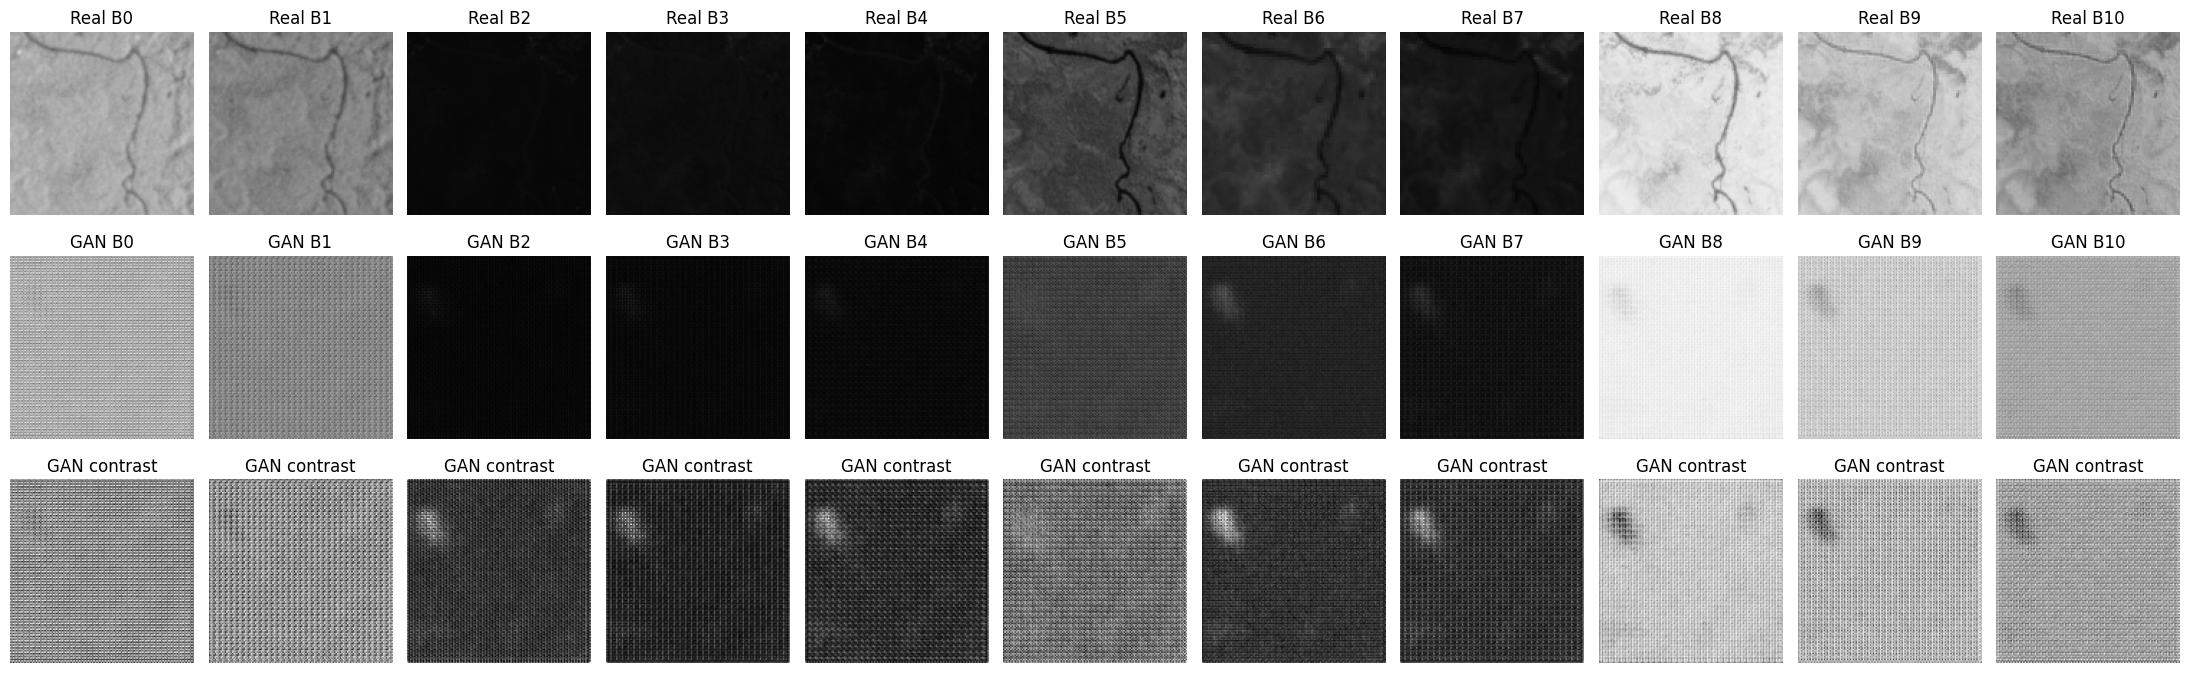

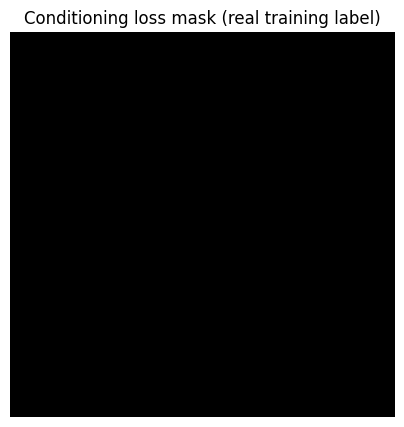

Visual audit displayed. No files modified.


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
GAN_DIR = os.path.join(ROOT, "Experiment_Results", "Amazon", "GAN")
YEARLY_DIR = os.path.join(
    ROOT, "Experiment_Results", "Amazon", "Patches", "Yearly_Extracted"
)

real = np.load(
    os.path.join(YEARLY_DIR, "Amazon_X_2020.npy"),
    mmap_mode="r"
)
folds = np.load(
    os.path.join(ROOT, "Experiment_Results", "Amazon", "Patches",
                 "Amazon_spatial_10fold_assignments.npy")
)
fake = np.load(os.path.join(GAN_DIR, "pilot_2020_synthetic_X.npy"))
masks = np.load(os.path.join(GAN_DIR, "pilot_2020_synthetic_Y.npy"))

real = np.asarray(real[folds >= 0])

# Compare one synthetic patch against a real training patch.
# This is a visual inspection, not a quantitative realism score.
real_idx = 0
fake_idx = 0

fig, axes = plt.subplots(3, 11, figsize=(22, 7))
for band in range(11):
    axes[0, band].imshow(real[real_idx, band], cmap="gray", vmin=0, vmax=1)
    axes[0, band].set_title(f"Real B{band}")
    axes[1, band].imshow(fake[fake_idx, band], cmap="gray", vmin=0, vmax=1)
    axes[1, band].set_title(f"GAN B{band}")
    axes[2, band].imshow(
        fake[fake_idx, band],
        cmap="gray",
        vmin=float(fake[fake_idx, band].min()),
        vmax=float(fake[fake_idx, band].max())
    )
    axes[2, band].set_title("GAN contrast")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

plt.figure(figsize=(5, 5))
plt.imshow(masks[fake_idx], cmap="gray", vmin=0, vmax=1)
plt.title("Conditioning loss mask (real training label)")
plt.axis("off")
plt.show()

print("Visual audit displayed. No files modified.")

In [ ]:

import os
import numpy as np

ROOT = "/content/drive/MyDrive/Forest_AI_Project"
PATCH_DIR = os.path.join(ROOT, "Experiment_Results", "Amazon", "Patches")
YEARLY_DIR = os.path.join(PATCH_DIR, "Yearly_Extracted")
GAN_DIR = os.path.join(ROOT, "Experiment_Results", "Amazon", "GAN")
os.makedirs(GAN_DIR, exist_ok=True)

# 1. Load original 2020 training-region patches
folds = np.load(
    os.path.join(PATCH_DIR, "Amazon_spatial_10fold_assignments.npy")
)
train_mask = folds >= 0

X_real = np.load(
    os.path.join(YEARLY_DIR, "Amazon_X_2020.npy")
)[train_mask]
Y_real = np.load(
    os.path.join(YEARLY_DIR, "Amazon_Y_2020.npy")
)[train_mask]

# 2. Load the 16 patches generated by our GAN pilot
X_gan = np.load(os.path.join(GAN_DIR, "pilot_2020_synthetic_X.npy"))
Y_gan = np.load(os.path.join(GAN_DIR, "pilot_2020_synthetic_Y.npy"))

assert X_real.shape[1:] == X_gan.shape[1:]
assert Y_real.shape[1:] == Y_gan.shape[1:]
assert len(X_gan) == len(Y_gan)

# 3. Combine original and synthetic samples
X_augmented = np.concatenate([X_real, X_gan], axis=0)
Y_augmented = np.concatenate([Y_real, Y_gan], axis=0)

# 4. Save as a separate pilot-augmented dataset
np.save(os.path.join(GAN_DIR, "pilot_2020_X_augmented.npy"), X_augmented)
np.save(os.path.join(GAN_DIR, "pilot_2020_Y_augmented.npy"), Y_augmented)

# 5. Report dataset growth
before = len(X_real)
added = len(X_gan)
after = len(X_augmented)

print("=" * 55)
print("FOREST AI — DATASET SIZE BEFORE AND AFTER GAN")
print("=" * 55)
print(f"Original training patches : {before}")
print(f"GAN-generated patches     : {added}")
print(f"Expanded dataset patches  : {after}")
print(f"Patch dimensions          : {X_augmented.shape[1:]}")
print(f"Target dimensions         : {Y_augmented.shape[1:]}")
print(f"Dataset increase          : {added / before * 100:.2f}%")
print(f"Feature data size         : {X_augmented.nbytes / (1024**2):.2f} MiB")
print("Saved feature dataset     : pilot_2020_X_augmented.npy")
print("Saved mask dataset        : pilot_2020_Y_augmented.npy")
print("=" * 55)

FOREST AI — DATASET SIZE BEFORE AND AFTER GAN
Original training patches : 468
GAN-generated patches     : 16
Expanded dataset patches  : 484
Patch dimensions          : (11, 128, 128)
Target dimensions         : (128, 128)
Dataset increase          : 3.42%
Feature data size         : 332.75 MiB
Saved feature dataset     : pilot_2020_X_augmented.npy
Saved mask dataset        : pilot_2020_Y_augmented.npy


In [ ]:
import os

ROOT = "/content/drive/MyDrive/Forest_AI_Project"

print("=== DATA INTEGRATION CHECK ===")

for folder, _, files in os.walk(ROOT):
    if any(x in folder.lower() for x in [
        "patches", "preprocessed", "yearly_extracted"
    ]):
        relevant = [
            f for f in files
            if f.endswith((".npy", ".npz", ".pt", ".pth"))
        ]
        if relevant:
            print(f"\n{folder}")
            for f in relevant[:12]:
                print("  ", f)

=== DATA INTEGRATION CHECK ===

/content/drive/MyDrive/Forest_AI_Project/Preprocessed
   normalization_stats.npz
   spatial_split_masks.npz
   normalization_stats_70_15_15.npz
   train_mask_70_15_15.npy

/content/drive/MyDrive/Forest_AI_Project/Preprocessed/GAN
   fold1_loss_patches.npz
   fold1_loss_patches_128_final.npz
   fold1_quality_check.npz

/content/drive/MyDrive/Forest_AI_Project/Preprocessed/Amazon
   amazon_normalization_stats_train_only.npz
   amazon_normalization_stats_buffered_train_only.npz
   amazon_cumulative_targets_buffered.npz
   amazon_temporal_inputs_buffered.npz

/content/drive/MyDrive/Forest_AI_Project/Preprocessed/Congo
   congo_temporal_inputs_2019_2025.npy
   congo_cumulative_loss_target_2025.npy
   congo_X_development_2019_2024.npy
   congo_Y_development_2025.npy
   congo_X_test_2019_2024.npy
   congo_Y_test_2025.npy
   congo_temporal_inputs_2019_2024_aligned.npy
   congo_valid_input_mask_2019_2024.npy
   congo_development_X_2019_2024_aligned.npy
   congo_d

In [ ]:

import os
import numpy as np

ROOT = "/content/drive/MyDrive/Forest_AI_Project"

FILES = [
    "Preprocessed/normalization_stats.npz",
    "Preprocessed/spatial_split_masks.npz",
    "Preprocessed/normalization_stats_70_15_15.npz",
    "Preprocessed/train_mask_70_15_15.npy",
    "Preprocessed/GAN/fold1_loss_patches.npz",
    "Preprocessed/GAN/fold1_loss_patches_128_final.npz",
    "Preprocessed/GAN/fold1_quality_check.npz",
    "Preprocessed/Amazon/amazon_cumulative_targets_buffered.npz",
    "Preprocessed/Amazon/amazon_temporal_inputs_buffered.npz",
    "Preprocessed/Congo/congo_X_development_2019_2024.npy",
    "Preprocessed/Congo/congo_Y_development_2025.npy",
    "Preprocessed/Congo/congo_X_test_2019_2024.npy",
    "Preprocessed/Congo/congo_Y_test_2025.npy",
    "Preprocessed/Congo/congo_development_X_2019_2024_aligned.npy",
    "Preprocessed/Congo/congo_development_Y_2025.npy",
    "Preprocessed/Congo/congo_test_X_2019_2024_aligned.npy",
    "Preprocessed/Congo/congo_test_Y_2025.npy",
]

print("=== EXISTING MODEL-READY DATA AUDIT ===")

for rel in FILES:
    path = os.path.join(ROOT, rel)
    if not os.path.exists(path):
        print(f"\nMISSING: {rel}")
        continue

    print(f"\n{rel}")
    if path.endswith(".npy"):
        arr = np.load(path, mmap_mode="r")
        print("  Shape:", arr.shape, "| dtype:", arr.dtype)
    elif path.endswith(".npz"):
        with np.load(path) as data:
            for key in data.files:
                arr = data[key]
                print(f"  {key}: shape={arr.shape}, dtype={arr.dtype}")

print("\nAudit only; no files modified.")


=== EXISTING MODEL-READY DATA AUDIT ===

Preprocessed/normalization_stats.npz
  means: shape=(11,), dtype=float64
  stds: shape=(11,), dtype=float64
  channels: shape=(11,), dtype=<U4

Preprocessed/spatial_split_masks.npz
  train_mask: shape=(3341, 3341), dtype=bool
  val_mask: shape=(3341, 3341), dtype=bool
  test_mask: shape=(3341, 3341), dtype=bool

Preprocessed/normalization_stats_70_15_15.npz
  means: shape=(11,), dtype=float64
  stds: shape=(11,), dtype=float64
  channels: shape=(11,), dtype=<U4

Preprocessed/train_mask_70_15_15.npy
  Shape: (3341, 3341) | dtype: bool

Preprocessed/GAN/fold1_loss_patches.npz
  X: shape=(811, 3, 11, 128, 128), dtype=float32
  Y: shape=(811, 128, 128), dtype=float32

Preprocessed/GAN/fold1_loss_patches_128_final.npz
  X: shape=(1166, 3, 11, 128, 128), dtype=float32
  Y: shape=(1166, 128, 128), dtype=float32

Preprocessed/GAN/fold1_quality_check.npz
  generated: shape=(8, 33, 64, 64), dtype=float32
  masks: shape=(8, 1, 64, 64), dtype=float32

Prepr

ValueError: Object arrays cannot be loaded when allow_pickle=False

In [ ]:

import os
import numpy as np

ROOT = "/content/drive/MyDrive/Forest_AI_Project"

FILES = [
    "Preprocessed/Amazon/amazon_temporal_inputs_buffered.npz",
    "Preprocessed/Congo/congo_temporal_inputs_2019_2025.npy",
    "Preprocessed/Congo/congo_X_development_2019_2024.npy",
    "Preprocessed/Congo/congo_Y_development_2025.npy",
    "Preprocessed/Congo/congo_X_test_2019_2024.npy",
    "Preprocessed/Congo/congo_Y_test_2025.npy",
    "Preprocessed/Congo/congo_development_X_2019_2024_aligned.npy",
    "Preprocessed/Congo/congo_development_Y_2025.npy",
    "Preprocessed/Congo/congo_test_X_2019_2024_aligned.npy",
    "Preprocessed/Congo/congo_test_Y_2025.npy",
]

for rel in FILES:
    path = os.path.join(ROOT, rel)
    print(f"\n{rel}")

    if not os.path.exists(path):
        print("  MISSING")
        continue

    if path.endswith(".npy"):
        arr = np.load(path, mmap_mode="r", allow_pickle=True)
        print("  Shape:", arr.shape, "| dtype:", arr.dtype)
        if arr.dtype == object:
            print("  Object array: inspect elements before using for training.")
    else:
        with np.load(path, allow_pickle=True) as data:
            for key in data.files:
                arr = data[key]
                print(f"  {key}: shape={arr.shape}, dtype={arr.dtype}")
                if arr.dtype == object:
                    print("    Object-array contents not expanded.")



Preprocessed/Amazon/amazon_temporal_inputs_buffered.npz


In [ ]:
import os

ROOT = "/content/drive/MyDrive/Forest_AI_Project"

for folder in [
    "Preprocessed",
    "Preprocessed/Amazon",
    "Preprocessed/Congo",
    "Experiment_Results/Amazon/Patches/Yearly_Extracted"
]:
    path = os.path.join(ROOT, folder)
    print(f"\n{folder}:")
    if os.path.exists(path):
        print("\n".join(os.listdir(path)[:15]))
    else:
        print("Not found")


Preprocessed:
normalization_stats.npz
spatial_split_masks.npz
Lunglei_GFW_lossyear_aligned_10m.tif
spatial_patch_index.csv
temporal_patch_index.csv
10fold_spatial_cv.csv
GAN
spatial_patch_index_70_15_15.csv
temporal_patch_index_70_15_15.csv
normalization_stats_70_15_15.npz
train_mask_70_15_15.npy
10fold_spatial_cv_70_15_15.csv
Amazon_GFW_lossyear_aligned_10m.tif
Amazon
CLAHE

Preprocessed/Amazon:
amazon_test_patch_index.csv
amazon_spatial_patch_index_70_15_15.csv
amazon_temporal_patch_index_70_15_15.csv
amazon_normalization_stats_train_only.npz
amazon_spatial_patch_index_70_15_15_buffered.csv
amazon_temporal_patch_index_70_15_15_buffered.csv
amazon_normalization_stats_buffered_train_only.npz
amazon_cumulative_targets_buffered.npz
amazon_temporal_inputs_buffered.npz

Preprocessed/Congo:
congo_temporal_inputs_2019_2025.npy
congo_cumulative_loss_target_2025.npy
congo_patch_index.csv
congo_patch_index_2025.csv
congo_spatial_split_manifest.csv
congo_X_development_2019_2024.npy
congo_Y_deve